# Cross-checking the MPS engine against TeNPy — conventions, DMRG and TEBD

**Marcin Płodzień** — Institute of Theoretical Physics, Jagiellonian University in Kraków  
[ORCID 0000-0002-0835-1644](https://orcid.org/0000-0002-0835-1644) · [github.com/MarcinPlodzien](https://github.com/MarcinPlodzien) · [www](https://chaos.if.uj.edu.pl/marcinplodzien/)

*Quantum Many-Body Simulation — Chapter 7 — Tensor networks*

<a href="https://colab.research.google.com/github/MarcinPlodzien/quantum-many-body-simulation/blob/main/ch07_tensor_networks/18b_engine_vs_tenpy_cross_check.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"></a>

## 1. Introduction

Our MPS engine was validated against exact diagonalisation on small chains and against exact
free-fermion solutions on long ones. A second, standard test in computational physics is to repeat the calculation with
an **independent, established code** written by other people and to compare the numbers. Such cross-checks catch errors
that a self-test cannot: a wrong factor in the Hamiltonian that the test shares with the code, a misread sign
convention, an observable computed on the wrong bond. They are also how a new code earns trust in a research group.

The library we compare with is TeNPy (Tensor Network Python), introduced in [[1]](#ref-1) and in its version 1 in
[[2]](#ref-2). It implements the same two algorithms as our engine: DMRG, introduced in [[3]](#ref-3), and TEBD, introduced in
[[4]](#ref-4), [[5]](#ref-5). Its source code is open, and we read it where a convention has to be pinned down.

A cross-check fails far more often because the two programs simulate *different problems* than because one of them is
wrong. Our Hamiltonians are written with Pauli matrices, TeNPy's with spin-1/2 operators $S^a=\sigma^a/2$; TeNPy's Ising
model has its axes rotated with respect to ours; entropies come in bits in one code and in nats in the other; and a
library may reorder the basis of a spin internally. The first half of the notebook builds the exact dictionary between
the two conventions and tests it on the full Hamiltonian matrix. The second half compares ground states and dynamics.

**Road map.**

1. The convention dictionary: spin operators versus Pauli matrices, the rotated Ising chain, basis order, entropy units,
   the Trotter splitting; a checkpoint on the full $64\times64$ Hamiltonian, and what happens with the naive mapping (Sec. 2).
2. DMRG: the transverse-field Ising chain against its exact free-fermion energy, including a case where both codes are right
   and still disagree (Sec. 3.1); the XXZ chain at $\Delta=1$ and $\Delta=2$: energies, entanglement, staggered correlations
   and the discarded weight as functions of $\chi$ (Sec. 3.2).
3. TEBD: the domain-wall and Néel quenches of the XX chain with the same time step and Trotter order in both codes, graded by
   the exact free-fermion solution (Sec. 4).
4. What the agreement of two codes proves and what it does not (Sec. 5).

The notebook assumes [notebook 18, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb).

### What you will learn
*Physics*

- The same chain written in Pauli matrices and in spin-1/2 operators differs by factors $4$ and $2$; the transverse-field
  Ising chain with field along $x$ and with field along $z$ are unitarily equivalent, with the same spectrum.
- In the ordered phase of a finite Ising chain the two lowest states are split by an exponentially small energy. A
  symmetric "cat" state and a symmetry-broken state then have almost the same energy but entanglement entropies that
  differ by one bit.

*Numerical methods*

- What has to match for two MPS codes to give the same numbers: the Hamiltonian, the start state, the bond dimension, the
  truncation rule, the Trotter splitting and its ordering.
- Why two DMRG runs at the same $\chi$ need not agree to rounding, and which tolerance is justified (the $\chi$-convergence of
  each code); why two TEBD runs agree to rounding until truncation sets in and then drift apart within the discarded weight.
- Why a third, analytic reference is needed: two codes with the same Trotter splitting share its error, and two codes with the
  same truncation rule can agree to ten digits on a completely wrong answer.

*Implementation practice*

- Wrapping a second library behind small functions whose docstrings state the convention mapping.
- Comparing named observables when a library may permute the basis internally.
- Reading the source of a library when its documentation leaves a convention open, and testing the library's own diagnostics.

## Configuration

Every notebook of this course starts with the same cell. Choose where to run (`DEVICE`) and the floating-point precision (`PRECISION`): `"double"` = `float64/complex128` (default, recommended for physics), `"single"` = `float32/complex64` (half the memory, faster on consumer GPUs, but watch the round-off). All code below derives its dtypes from `RDTYPE`/`CDTYPE` and its check tolerances from `TOL`, so nothing else needs to change.

In [1]:
# ==============================================================================
# CONFIGURATION  -- adapt to your hardware, then run the notebook top to bottom
# ==============================================================================
DEVICE    = "auto"     # "auto": use a GPU if JAX finds one, else CPU | "cpu" | "gpu"
PRECISION = "double"   # "double": float64/complex128 | "single": float32/complex64

import os
if DEVICE == "cpu":
    os.environ["JAX_PLATFORMS"] = "cpu"          # must be set BEFORE jax is imported

import string
from functools import partial

import math
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

# Precision is configurable: "double" = float64/complex128 (default; needed for long time evolutions and
# tight validation), "single" = float32/complex64 (half the memory, faster on consumer GPUs).
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # the 52 einsum index labels a-z, A-Z

import time
import matplotlib.pyplot as plt

if DEVICE == "gpu" and jax.default_backend() == "cpu":
    print("WARNING: DEVICE='gpu' requested but JAX found no GPU -- running on CPU.")
print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | devices: {jax.devices()}")
print(f"precision: {PRECISION} -> real {RDTYPE.__name__}, complex {CDTYPE.__name__}, check tolerance TOL={TOL:g}")


JAX 0.11.0 | backend: cpu | devices: [CpuDevice(id=0)]
precision: double -> real float64, complex complex128, check tolerance TOL=1e-10


In [2]:
#| code-fold: true
#| code-summary: "Engine recap — the simulator primitives used in this notebook (click to expand)"
# ==============================================================================
# ENGINE RECAP: the functions of quantum_engine.py (SmoQ.jax) used in this notebook.
# All of them are collected, with their mathematics, in the notebook
# 'Building the quantum simulator engine'.
# States are rank-N tensors of shape (2,)*N; every operator acts through ONE einsum.
# ==============================================================================
# ----------------------------------------------------------------------------
# Elementary matrices: Paulis, Clifford generators, rotations
# ----------------------------------------------------------------------------
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
S = jnp.array([[1, 0], [0, 1j]], dtype=CDTYPE)                      # phase gate, S^2 = Z
XX = jnp.kron(X, X)
YY = jnp.kron(Y, Y)
ZZ = jnp.kron(Z, Z)

# ----------------------------------------------------------------------------
# Variational circuits: ansatz, gradients, optimizers
# ----------------------------------------------------------------------------
_SPIN_MPS = {"0": [1, 0], "1": [0, 1], "+": [1, 1], "-": [1, -1]}      # same characters as product_state
LAM_CUT = 100 * float(jnp.finfo(RDTYPE).eps)                           # Schmidt values below this are padding
def product_mps(spec, chi):
    """Product state |spec[0]> |spec[1]> ... as a padded MPS  (B[N,chi,2,chi], lam[N+1,chi]).
    MATH   B[j][0, s, 0] = v_j[s], all other entries zero;  every cut has the single Schmidt value 1.
    '0' = spin up (Z=+1), '1' = spin down (Z=-1), '+'/'-' = eigenstates of X."""
    N = len(spec)
    B = np.zeros((N, chi, 2, chi), dtype=complex)
    for j, c in enumerate(spec):
        v = np.array(_SPIN_MPS[c], dtype=complex)
        B[j, 0, :, 0] = v / np.linalg.norm(v)
    lam = np.zeros((N + 1, chi))
    lam[:, 0] = 1.0
    return jnp.asarray(B, dtype=CDTYPE), jnp.asarray(lam, dtype=RDTYPE)

def mps_expect_sites(B, lam, O):
    """<O_j> for ALL sites j at once.   MATH  theta_j = lam[j] B[j];  <O_j> = sum theta*[a,t,b] O[t,s] theta[a,s,b].
    COST O(N chi^2).  The letter j in the einsum is a batch index (one independent contraction per site)."""
    theta = lam[:-1, :, None, None] * B
    return jnp.real(jnp.einsum("jatb,ts,jasb->j", jnp.conj(theta), jnp.asarray(O, dtype=B.dtype), theta))

def mps_expect_bonds(B, lam, h_bonds):
    """<h_j> for all N-1 nearest-neighbour operators h_j (array (N-1,4,4)) at once; sum = energy.
    MATH  theta[a,s,t,b] = lam[j][a] B[j][a,s,m] B[j+1][m,t,b];   <h> = sum theta*[a,s,t,b] h[s,t,u,v] theta[a,u,v,b]."""
    theta = jnp.einsum("ja,jasm,jmtb->jastb", lam[:-2].astype(B.dtype), B[:-1], B[1:])
    h = jnp.asarray(h_bonds, dtype=B.dtype).reshape(-1, 2, 2, 2, 2)
    return jnp.real(jnp.einsum("jastb,jstuv,jauvb->j", jnp.conj(theta), h, theta))

def mps_entropies(lam):
    """Entanglement entropy (bits) of every cut, directly from the stored Schmidt values:
    S_j = -sum_k lam[j,k]^2 log2 lam[j,k]^2   (0 log 0 := 0 handles the zero padding)."""
    p = lam ** 2
    return -jnp.sum(jnp.where(p > 0, p * jnp.log2(jnp.where(p > 0, p, 1.0)), 0.0), axis=1)

def mps_correlator(B, lam, O, i, P, j):
    """<O_i P_j> for i < j (static ints) with a transfer-matrix sweep between the two sites.  COST O((j-i) chi^3).
    O and P must be Hermitian: the product O_i P_j on two different sites is then Hermitian and its expectation value
    real, which is what is returned (the real part; a non-Hermitian pair such as sigma+ sigma- would lose its
    imaginary part).  i >= j raises ValueError (i == j is the single-site <O P>, use mps_expect_sites)."""
    i, j = int(i), int(j)
    if not 0 <= i < j < B.shape[0]:                                   # j <= i silently returned a wrong number
        raise ValueError(f"mps_correlator needs 0 <= i < j < {B.shape[0]}, got i={i}, j={j}")
    O, P = jnp.asarray(O, dtype=B.dtype), jnp.asarray(P, dtype=B.dtype)
    theta = lam[i][:, None, None] * B[i]
    E = jnp.einsum("atb,ts,asc->bc", jnp.conj(theta), O, theta)       # open legs: right bonds (bra b, ket c)
    for k in range(i + 1, j):
        E = jnp.einsum("bc,bsd,cse->de", E, jnp.conj(B[k]), B[k])     # push through site k
    return jnp.real(jnp.einsum("bc,btd,ts,csd->", E, jnp.conj(B[j]), P, B[j]))

def xxz_mpo(N, Jxx=1.0, Jyy=1.0, Jzz=1.0, hx=0.0, hz=0.0):
    """MPO of H = sum_i (Jxx X X + Jyy Y Y + Jzz Z Z)_{i,i+1} + sum_i (hx X_i + hz Z_i), open chain, Pauli convention.

    RETURNS  W of shape (N, D, D, 2, 2), D = 5:  W[j, v, w, s_out, s_in] = the operator at site j for the move v -> w.
             States of the finite-state machine: 4 = nothing placed, 1/2/3 = X/Y/Z placed on the previous site, 0 = complete.
             Site 0 keeps only row 4 and site N-1 only column 0 (all other entries zero), so all sites have the same shape.
    CONVENTION (used by every MPO routine: mpo_to_dense, mpo_expectation, boundary_environments, dmrg)
             the START state of the machine is the LAST index D-1 and the END state is index 0, for any D.
    """
    D = 5
    W = jnp.zeros((D, D, 2, 2), dtype=CDTYPE)
    W = W.at[0, 0].set(I2).at[4, 4].set(I2)                                 # stay: identities
    W = W.at[1, 0].set(X).at[2, 0].set(Y).at[3, 0].set(Z)                   # second half of a bond -> complete
    W = W.at[4, 1].set(Jxx * X).at[4, 2].set(Jyy * Y).at[4, 3].set(Jzz * Z)  # first half of a bond
    W = W.at[4, 0].set(hx * X + hz * Z)                                     # a single-site term, complete at once
    Ws = jnp.stack([W] * N)
    Ws = Ws.at[0].set(jnp.zeros_like(W).at[4].set(W[4]))                   # left boundary: only row 4
    Ws = Ws.at[N - 1].set(jnp.zeros_like(W).at[:, 0].set(W[:, 0]))         # right boundary: only column 0
    return Ws

def mpo_to_dense(Ws):
    """Contract an MPO into the dense 2^N x 2^N matrix (validation only, small N).
    MATH  M_(j)[w] = sum_v M_(j-1)[v] (x) W[j][v, w]   starting from row D-1 of site 0; the result is column 0 after the last site.
    CONVENTION  start state = last index D-1, end state = index 0 (as in xxz_mpo), for any bond dimension D."""
    N, D = Ws.shape[0], Ws.shape[1]
    M = Ws[0][D - 1]                                                        # (w, s_out, s_in) after site 0: start state D-1
    for j in range(1, N):
        M = jnp.einsum("vab,vwcd->wacbd", M, Ws[j]).reshape(D, 2 ** (j + 1), 2 ** (j + 1))
    return M[0]

def left_env_update(L, A, W):
    """L_{j+1}[b,w,b'] = sum L_j[a,v,a'] A[a,s,b] W[v,w,t,s] conj(A)[a',t,b']

    Letters  a v x = L_j (x = a', the bra bond);  a s b = A (ket);  v w t s = W (t = s_out, s = s_in);  x t c = conj(A) (bra, c = b').
             The BRA tensor carries the OUTPUT leg of W, because <psi|H|psi> = sum conj(A) (W A).
    """
    return jnp.einsum("avx,asb,vwts,xtc->bwc", L, A, W, jnp.conj(A))

def right_env_update(R, B, W):
    """R_j[a,v,a'] = sum B[a,s,b] W[v,w,t,s] conj(B)[a',t,b'] R_{j+1}[b,w,b']

    Letters  a s b = B (ket);  v w t s = W (t = s_out, s = s_in);  x t c = conj(B) (bra, x = a', c = b');  b w c = R_{j+1}.
    """
    return jnp.einsum("asb,vwts,xtc,bwc->avx", B, W, jnp.conj(B), R)

def boundary_environments(chi, D):
    """L_0 and R_N in the padded format (chi, D, chi): L_0[0, D-1, 0] = 1 (nothing placed), R_N[0, 0, 0] = 1 (complete)."""
    L0 = jnp.zeros((chi, D, chi), dtype=CDTYPE).at[0, D - 1, 0].set(1.0)
    RN = jnp.zeros((chi, D, chi), dtype=CDTYPE).at[0, 0, 0].set(1.0)
    return L0, RN

def heff_apply(L, W1, W2, R, theta):
    """(H_eff theta)[a',s',t',b'] = sum L[a,v,a'] W1[v,w,s',s] W2[w,u,t',t] R[b,u,b'] theta[a,s,t,b]
    Letters: a v x = L (x = a'), v w y s = W1 (y = s'), w u z t = W2 (z = t'), b u q = R (q = b'), a s t b = theta.
    COST O(chi^3 D d^2) with the contraction order chosen by optimize="optimal"; the (4 chi^2)^2 matrix is never formed."""
    return jnp.einsum("avx,vwys,wuzt,buq,astb->xyzq", L, W1, W2, R, theta, optimize="optimal")

def lanczos_lowest(matvec, v0, m, mask=None, key=None):
    """Lowest eigenpair (E, x) of a Hermitian operator given only matvec, from m Lanczos steps started at v0.

    MATH    beta_j v_{j+1} = H v_j - alpha_j v_j - beta_{j-1} v_{j-1}  (Lanczos recurrence), full reorthogonalisation (twice);
            Ritz vector x = sum_j s_j v_j of the lowest eigenvector s of the tridiagonal T.
    BREAKDOWN  beta_j <= 1e-12 ||H||, with ||H|| estimated by the largest ||H v_j|| seen (a RELATIVE test: the rounding
            residual of an exhausted Krylov space grows with ||H||).  The Krylov space K is then invariant, but it need
            not contain the lowest eigenvector (v0 orthogonal to it, e.g. v0 an eigenvector or in another symmetry
            sector).  Lanczos therefore RESTARTS from a random vector of the allowed space (`mask`), orthogonalised
            against K, and writes beta_j = 0 into T: T becomes block diagonal and every Ritz value belongs to H.  Only if
            nothing is left (the whole allowed space is exhausted) do the remaining rows of T get a diagonal far above
            the spectrum, so that their spurious eigenvalues cannot be the lowest.
    ARGUMENTS  mask (shape of v0, 0/1, optional): the subspace H acts on; the restart vectors are drawn inside it.
            key: PRNG key of the restart vectors (default PRNGKey(0): deterministic).
    """
    shape = v0.shape
    v0 = (v0 / jnp.linalg.norm(v0)).reshape(-1)
    mask = jnp.ones(v0.size, dtype=RDTYPE) if mask is None else jnp.asarray(mask, dtype=RDTYPE).reshape(-1)
    key = jax.random.PRNGKey(0) if key is None else key
    V0 = jnp.zeros((m, v0.size), dtype=v0.dtype).at[0].set(v0)

    def orthogonalise(w, V):                                     # w <- w - sum_i v_i <v_i|w>, twice (rounding); V holds the v_i as ROWS
        w = w - jnp.conj(V @ jnp.conj(w)) @ V
        return w - jnp.conj(V @ jnp.conj(w)) @ V

    def body(carry, j):
        V, v, v_prev, beta_prev, alive, hnorm = carry
        Hv = matvec(v.reshape(shape)).reshape(-1)
        hnorm = jnp.maximum(hnorm, jnp.linalg.norm(Hv))          # lower bound of ||H||: the scale of the breakdown test
        alpha = jnp.real(jnp.vdot(v, Hv))
        w = orthogonalise(Hv - alpha * v - beta_prev * v_prev, V)
        beta = jnp.linalg.norm(w)
        cont = beta > 1e-12 * hnorm                              # False: breakdown, K is an invariant subspace

        def restart(_):                                          # random vector of the allowed space, orthogonal to K
            r = mask * jax.random.normal(jax.random.fold_in(key, j), (v.size,), dtype=RDTYPE)
            r = orthogonalise(r.astype(V.dtype), V)
            rn = jnp.linalg.norm(r)
            fresh = rn > 1e-8 * jnp.sqrt(jnp.sum(mask))          # False: the allowed space is exhausted
            return r / jnp.where(fresh, rn, 1.0), fresh

        v_next, fresh = lax.cond(cont, lambda _: (w / jnp.where(cont, beta, 1.0), jnp.array(True)), restart, None)
        v_next = jnp.where(alive & (cont | fresh), v_next, 0.0)
        b_out = jnp.where(alive & cont, beta, 0.0)               # a restart decouples the new block: T_{j,j+1} = 0
        V = V.at[j + 1].set(v_next, mode="drop")                 # at j = m-1 the index j+1 is out of range; "drop" discards that write
        return (V, v_next, v, b_out, alive & (cont | fresh), hnorm), (alpha, b_out, alive)

    init = (V0, v0, jnp.zeros_like(v0), jnp.zeros((), dtype=RDTYPE), jnp.array(True), jnp.zeros((), dtype=RDTYPE))
    (V, _, _, _, _, hnorm), (alphas, betas, used) = lax.scan(body, init, jnp.arange(m))
    alphas = jnp.where(used, alphas, 1e3 * (1.0 + hnorm))      # unused rows of T: far above every Ritz value
    evals_T, evecs_T = jnp.linalg.eigh(jnp.diag(alphas) + jnp.diag(betas[:-1], 1) + jnp.diag(betas[:-1], -1))   # Ritz values and vectors of T
    x = evecs_T[:, 0].astype(V.dtype) @ V                    # Ritz vector of the lowest Ritz value, in the big space
    return evals_T[0], (x / jnp.linalg.norm(x)).reshape(shape)

def split_two_site(theta, chi, move_right, support=None):
    """theta[a,s,t,b] (padded, shape (chi,2,2,chi)) -> two tensors (chi,2,chi), Schmidt values, discarded weight.

    MATH   theta_{(as),(tb)} = U S V^dag, keep chi values:  S <- S[:chi]/||S[:chi]||,  eps = sum_{k>=chi} S_k^2 / sum_k S_k^2
           move_right:  left = U (left-canonical),     right = S V^dag (carries the centre)
           move_left :  left = U S (carries centre),   right = V^dag (right-canonical)
    COMPLETION  The columns of U (move_right) or rows of V^dag (move_left) whose Schmidt value vanishes (< LAM_CUT) are
           replaced by an orthonormal completion INSIDE the space of genuine block states, P = {(a,s): support[a]}
           (move_right) or {(t,b): support[b]} (move_left): the orthonormal basis of (1 - U_k U_k^dag) P.  These
           directions carry weight zero now; a later step can give them weight, which is how the bond dimension grows
           faster than the factor 2 per half sweep allowed by the Schmidt rank alone.  Columns beyond dim P are EXACT
           zeros.  The completion that LAPACK returns would mix in padded (zero-norm) block "states"; H_eff, which
           assumes orthonormal block bases, then has a spurious eigenvalue 0 on them (see dmrg).
    ARGUMENTS  chi must equal theta.shape[0] (the storage size): the routine always keeps exactly chi of the 2*chi values.
           support (chi,) bool: the bond indices of the outer bond (a for move_right, b for move_left) that are block
           states (the others are padding); default: all.
    """
    U, S, Vh = jnp.linalg.svd(theta.reshape(2 * chi, 2 * chi), full_matrices=False)
    weight = S ** 2
    eps = jnp.sum(weight[chi:]) / jnp.sum(weight)
    S = S[:chi] / jnp.sqrt(jnp.sum(weight[:chi]))
    keep = S > LAM_CUT                                       # a prefix: S is sorted
    S = jnp.where(keep, S, 0.0)
    support = jnp.ones(chi, dtype=bool) if support is None else support
    if move_right:
        Q, p = U[:, :chi], jnp.repeat(support, 2)            # isometry U: rows (a, s), allowed rows support[a]
    else:
        Q, p = jnp.conj(Vh[:chi]).T, jnp.tile(support, 2)    # isometry V: rows (t, b), allowed rows support[b]
    p = p.astype(Q.dtype)
    Qk = Q * keep[None, :] * p[:, None]                      # kept vectors (exactly zero outside P)
    C = jnp.diag(p) - Qk @ (jnp.conj(Qk).T * p[None, :])     # (1 - Qk Qk^dag) P: its range is the completion space
    Uc, sc, _ = jnp.linalg.svd(C)
    Uc = Uc * (sc > 0.5)[None, :]                            # singular values are 1 (completion) or 0 (nothing): drop the 0s
    r = jnp.sum(keep)
    fill = jnp.take(Uc, jnp.clip(jnp.arange(chi) - r, 0, 2 * chi - 1), axis=1)   # completion vector k - r into column k >= r
    Q = jnp.where(keep[None, :], Qk, fill)
    if move_right:
        return Q.reshape(chi, 2, chi), (S[:, None] * Vh[:chi] * keep[:, None]).reshape(chi, 2, chi), S, eps
    return (U[:, :chi] * S[None, :]).reshape(chi, 2, chi), jnp.conj(Q).T.reshape(chi, 2, chi), S, eps

_LOCAL_STEP_CACHE = {}                                             # one XLA compilation per (chi, m, direction)
def make_local_step(chi, m, move_right):
    """Compiled DMRG step on the bond (j, j+1): contract, solve H_eff theta = E theta (Lanczos, m steps), split.

    The compiled step depends only on (chi, m, direction) -- never on the site, the Hamiltonian or the field -- so
    it is built once and cached.  Without the cache every call of `dmrg`, hence every point of a parameter scan,
    pays a fresh XLA compilation, which dominates the run time although the arithmetic is identical."""
    key = (chi, m, move_right)
    if key in _LOCAL_STEP_CACHE:
        return _LOCAL_STEP_CACHE[key]

    @jax.jit
    def step(L, W1, W2, R, M1, M2):
        theta = jnp.einsum("asm,mtb->astb", M1, M2)                                   # 1. two-site tensor
        used_L, used_R = jnp.any(L != 0, axis=(0, 1)), jnp.any(R != 0, axis=(0, 1))   #    bond indices that are block states
        mask = used_L[:, None, None, None] & used_R[None, None, None, :] & jnp.ones(theta.shape, dtype=bool)
        E, theta = lanczos_lowest(lambda t: heff_apply(L, W1, W2, R, t), theta, m, mask)   # 2. local ground state
        left, right, S, eps = split_two_site(theta, chi, move_right, used_L if move_right else used_R)   # 3. split, move the centre
        return left, right, S, eps, E

    _LOCAL_STEP_CACHE[key] = step
    return step

def mps_recanonicalise(B):
    """Exact right-canonical form and the TRUE Schmidt values of every cut, for a padded MPS whose site 0 carries the norm.

    MATH
        Left sweep  j = 0..N-2:   A[j]_{(a s), b} = Q R   (QR);   A[j] <- Q (left-canonical);   A[j+1] <- R A[j+1].
        After it, sites 0..N-2 are left-canonical and the whole norm sits on site N-1.
        Right sweep j = N-1..1:   A[j]_{a, (s b)} = U S V^dag   (SVD);   B[j] <- V^dag;   lam[j] <- S;   A[j-1] <- A[j-1] U S.
        At step j everything left of the cut is left-canonical and everything right of it right-canonical, so
        S are exactly the Schmidt values of the cut left of site j (no stored value from an earlier, different state).
        No truncation can occur: every matrix has rank <= chi, and all chi values are kept.  lam[0] = lam[N] = (1,0,..).
        Singular values below LAM_CUT * S_max (rounding zeros) are set to exact zero with their rows of V^dag, so that the
        padding of the returned tensors is exactly zero (the completion LAPACK returns there is arbitrary).
    WHY    `dmrg` records lam[j] at the split of bond j during the right-to-left half sweep; the later steps at bonds
           j-1, ..., 1 change the left block of that cut, so the recorded values describe an intermediate state.
           Likewise `state_to_mps` with truncation stores lam[j] before cut j-1 is truncated.  This pass makes
           (B, lam) consistent, so that the lam-based observables (mps_expect_sites, mps_expect_bonds, mps_entropies,
           mps_correlator) are those of the state that B encodes.  The state itself is unchanged (to rounding).
    ARGUMENTS  B (N, chi, 2, chi) any padded MPS whose left boundary leg is index 0 and right boundary leg index 0.
    RETURNS    B (N, chi, 2, chi) right-canonical on sites 1..N-1 (site 0 = centre, holds the norm), lam (N+1, chi).
    COST       N QR and N SVD of (2chi x chi) matrices: O(N chi^3).
    """
    N, chi = B.shape[0], B.shape[1]
    A = list(B)
    for j in range(N - 1):                                             # left sweep: QR, push R to the right
        Q, R = jnp.linalg.qr(A[j].reshape(chi * 2, chi))
        A[j] = Q.reshape(chi, 2, chi)
        A[j + 1] = jnp.einsum("ab,bsc->asc", R, A[j + 1])
    lam = jnp.zeros((N + 1, chi), dtype=RDTYPE).at[0, 0].set(1.0).at[N, 0].set(1.0)
    for j in range(N - 1, 0, -1):                                      # right sweep: SVD, push U S to the left
        U, S, Vh = jnp.linalg.svd(A[j].reshape(chi, 2 * chi), full_matrices=False)
        keep = S > LAM_CUT * S[0]                                      # beyond the rank: exact zeros (see split_two_site)
        S, Vh = jnp.where(keep, S, 0.0), Vh * keep[:, None]
        A[j] = Vh.reshape(chi, 2, chi)
        lam = lam.at[j].set(S.astype(RDTYPE))
        A[j - 1] = jnp.einsum("asb,bc->asc", A[j - 1], U * S[None, :].astype(U.dtype))
    A[0] = A[0].at[1:].set(0.0)                                        # unused rows of the dummy left bond: exactly zero
    return jnp.stack(A), lam

def dmrg(W, M, chi, n_sweeps, m=20, trace=False, check_convergence=True):
    """Two-site DMRG for the MPO W (N, D, D, 2, 2), starting from the padded MPS M (N, chi, 2, chi).

    RETURNS  B (N, chi, 2, chi) right-canonical, lam (N+1, chi) Schmidt values of all bonds, history list of
             (sweep, direction, bond j, energy, discarded weight, number of non-zero Schmidt values) for every local step.
    FINAL PASS  The S of the split at bond j+1 is recorded during the right-to-left half sweep, but the later steps
             at bonds j, ..., 0 change the left block of that cut, so the recorded values belong to an intermediate
             state; they are exact only after convergence at a chi where nothing is truncated.  `dmrg` therefore ends
             with `mps_recanonicalise` (exact, O(N chi^3), state unchanged), which recomputes lam from the returned B.
    START    M is first brought to right-canonical form by `mps_recanonicalise` and normalised (any gauge and norm are
             accepted; the padding becomes exact zeros).  A zero or non-finite start raises ValueError.
    SAFETY   The local problem H_eff theta = E theta is the projected one only if every bond index is an orthonormal
             block state or exactly zero (`split_two_site`); otherwise zero-norm directions add a spurious eigenvalue 0,
             which is the lowest one whenever the physical local energies are positive (e.g. a Neel start of the
             ferromagnetic TFIM), and the state collapses to the zero vector.  A local step whose Schmidt values are not
             normalised or whose energy is not finite, and a final state whose norm is not 1, raise RuntimeError.
    SYMMETRY Lanczos keeps the symmetry sector of its start vector (e.g. S^z_tot for an XXZ chain).  On a breakdown it
             restarts from a random vector (`lanczos_lowest`), which happens on the short bonds near the chain ends and
             for an eigenstate start; this lets the state leave the sector of the start, but nothing guarantees it.
    CONVERGENCE  The sweeps stop after n_sweeps.  With check_convergence, the energy change dE of the last sweep is
             compared with the truncation error of the energy, which is about eps_max |E| (eps_max = largest discarded
             weight of the last sweep): the run counts as converged if |dE| <= max(10 eps_max |E|, 100 eps_mach |E|),
             the second term being the rounding of E.  Otherwise one line is printed (not raised).  A single sweep
             has no energy change to compare and is reported as not checked.
    """
    N, D = W.shape[0], W.shape[1]
    M, _ = mps_recanonicalise(jnp.asarray(M, dtype=CDTYPE))        # right-canonical, padding exactly zero
    nrm = float(jnp.linalg.norm(M[0]))                             # site 0 carries the norm
    if not np.isfinite(nrm) or nrm < 1e-12:
        raise ValueError(f"dmrg: the start MPS has norm {nrm:.3e} (zero or not finite)")
    M = M.at[0].set(M[0] / nrm)
    tol = float(jnp.sqrt(jnp.finfo(RDTYPE).eps))                   # 1.5e-8 (double), 3.5e-4 (single)

    def check(S):                                                  # raise instead of continuing with a broken step
        h, norm2 = history[-1], float(jnp.sum(S ** 2))
        if not (np.isfinite(h[3]) and abs(norm2 - 1.0) < tol):
            raise RuntimeError(f"dmrg: local step (sweep {h[0]}, {h[1]}, bond {h[2]}) gave E = {h[3]}, sum S^2 = {norm2}")

    step_right, step_left = make_local_step(chi, m, True), make_local_step(chi, m, False)
    L, R = [None] * (N + 1), [None] * (N + 1)
    L[0], R[N] = boundary_environments(chi, D)
    for j in range(N - 1, 1, -1):                                  # right environments of the initial state
        R[j] = right_env_update(R[j + 1], M[j], W[j])
    M = list(M)
    lam = jnp.zeros((N + 1, chi), dtype=RDTYPE).at[0, 0].set(1.0).at[N, 0].set(1.0)
    history = []
    for sweep in range(n_sweeps):
        for j in range(0, N - 1):                                  # ---- left -> right
            M[j], M[j + 1], S, eps, E = step_right(L[j], W[j], W[j + 1], R[j + 2], M[j], M[j + 1])
            L[j + 1] = left_env_update(L[j], M[j], W[j])           # the only environment that changes
            history.append((sweep, "->", j, float(E), float(eps), int(jnp.sum(S > 1e-12))))
            check(S)
        for j in range(N - 2, -1, -1):                             # ---- right -> left
            M[j], M[j + 1], S, eps, E = step_left(L[j], W[j], W[j + 1], R[j + 2], M[j], M[j + 1])
            R[j + 1] = right_env_update(R[j + 2], M[j + 1], W[j + 1])
            lam = lam.at[j + 1].set(S)                             # Schmidt values of the bond left of site j+1
            history.append((sweep, "<-", j, float(E), float(eps), int(jnp.sum(S > 1e-12))))
            check(S)
        if trace:
            last = [h for h in history if h[0] == sweep]
            print(f"   sweep {sweep}:  E = {last[-1][3]:.12f}   largest discarded weight {max(h[4] for h in last):.1e}   "
                  f"largest bond dimension {max(h[5] for h in last)}")
    B, lam = mps_recanonicalise(jnp.stack(M))                     # the lam recorded above is stale: recompute it from B
    nrm = float(jnp.linalg.norm(B[0]))
    if not abs(nrm - 1.0) < tol:
        raise RuntimeError(f"dmrg: the final MPS has norm {nrm:.3e} instead of 1")
    if check_convergence:                                          # energy change of the last sweep vs its truncation
        if n_sweeps < 2:
            print(f"dmrg: convergence not checked after {n_sweeps} sweep(s) (it needs the energy change between two); "
                  "run more sweeps")
        else:
            E, dE = history[-1][3], history[-1][3] - [h[3] for h in history if h[0] == n_sweeps - 2][-1]
            eps = max(h[4] for h in history if h[0] == n_sweeps - 1)
            if abs(dE) > max(10 * eps * abs(E), 100 * float(jnp.finfo(RDTYPE).eps) * abs(E)):
                print(f"dmrg: not converged after {n_sweeps} sweeps (last-sweep energy change {dE:.1e} vs largest "
                      f"discarded weight {eps:.1e}); run more sweeps")
    return B, lam, history

def expm_herm(h, tau):
    """exp(-i tau h) for a small Hermitian matrix via its eigendecomposition h = V w V^dag."""
    w, v = jnp.linalg.eigh(jnp.asarray(h, dtype=CDTYPE))
    return (v * jnp.exp(-1j * tau * w)) @ v.conj().T

def two_site_update(lamL, B1, B2, G):
    """Apply a two-site gate to neighbouring MPS tensors and truncate back to bond dimension chi.

    MATH
        C[a,s,t,b]      = sum_{m,s',t'} G[s,t,s',t'] B1[a,s',m] B2[m,t',b]        (merge + gate)
        theta[a,s,t,b]  = lamL[a] C[a,s,t,b]                                       (mixed-canonical wave function)
        theta_{(as),(tb)} = sum_k U_{(as),k} S_k Vh_{k,(tb)}                       (SVD; S = new Schmidt values)
        keep k < chi:   lam' = S/||S_kept||,  B2' = Vh,  B1' = C . conj(B2') / ||S_kept||   (Hastings: no 1/lam)
        eps = sum_{k>=chi} S_k^2 / sum_k S_k^2                                     (discarded weight)
    ARGUMENTS   lamL (chi,) Schmidt values LEFT of the first site; B1, B2 (chi,2,chi); G (2,2,2,2) = U4.reshape.
    RETURNS     B1', B2', lam' (Schmidt values of the bond between the two sites), eps.
    COST        SVD of a (2chi x 2chi) matrix: O(chi^3); contractions O(chi^3).
    JAX         static shapes (chi is the array size, never data-dependent) -> jit / vmap / scan friendly.
    """
    chi = B1.shape[0]
    C = jnp.einsum("asm,mtb->astb", B1, B2)                           # (a) merge the two sites
    C = jnp.einsum("stuv,auvb->astb", G, C)                           # (b) apply the gate
    theta = lamL[:, None, None, None] * C                             #     weight with the left Schmidt values
    U, S, Vh = jnp.linalg.svd(theta.reshape(2 * chi, 2 * chi), full_matrices=False)   # (c) split
    weight = S ** 2
    kept = jnp.sum(weight[:chi])
    eps = jnp.sum(weight[chi:]) / jnp.sum(weight)                     # discarded Schmidt weight (never negative)
    nrm = jnp.sqrt(kept)
    lam_new = S[:chi] / nrm                                           # truncate + renormalise to norm 1
    mask = lam_new > LAM_CUT                                          # True on used bond indices, False on padding
    lam_new = jnp.where(mask, lam_new, 0.0)
    B2_new = Vh[:chi].reshape(chi, 2, chi) * mask[:, None, None]      # right-canonical by construction
    B1_new = jnp.einsum("astb,ktb->ask", C, jnp.conj(B2_new)) / nrm   # Hastings: C.V instead of (1/lam) U S
    return B1_new, B2_new, lam_new.astype(lamL.dtype), eps

def bond_hamiltonians(N, Jxx=0.0, Jyy=0.0, Jzz=0.0, hx=0.0, hz=0.0):
    """Two-site terms h_j (array (N-1,4,4)) with  sum_j h_j = H,
        H = sum_j (Jxx XX + Jyy YY + Jzz ZZ)_{j,j+1} + sum_j (hx X_j + hz Z_j)      (Pauli convention, open chain).
    The single-site fields are split equally between the two bonds that contain the site."""
    one = hx * X + hz * Z
    hs = []
    for j in range(N - 1):
        cL = 1.0 if j == 0 else 0.5
        cR = 1.0 if j == N - 2 else 0.5
        hs.append(Jxx * XX + Jyy * YY + Jzz * ZZ + cL * jnp.kron(one, I2) + cR * jnp.kron(I2, one))
    return jnp.stack(hs)

def bond_gates(h_bonds, tau):
    """exp(-i tau h_j) for every bond, as rank-4 gate tensors G[j][s,t,s',t'] (shape (N-1,2,2,2,2)).
    JAX: vmap turns the single-matrix function expm_herm into a batched one."""
    return jax.vmap(lambda h: expm_herm(h, tau))(h_bonds).reshape(-1, 2, 2, 2, 2)

def tebd_layer(B, lam, G, idx):
    """Apply the gates G[k] to the bonds (idx[k], idx[k]+1) -- all bonds of one parity, in parallel.
    JAX   gather with integer-array indexing, ONE vmapped two_site_update (batched einsums + batched SVD),
          scatter with .at[].set().
    RETURNS  the new (B, lam), the summed discarded weight sum_b eps_b of the layer, and sum_b sqrt(eps_b),
             the quantity that enters the triangle-inequality bound on the accumulated truncation error."""
    B1, B2, lam_new, eps = jax.vmap(two_site_update)(lam[idx], B[idx], B[idx + 1], G)
    B = B.at[idx].set(B1).at[idx + 1].set(B2)
    lam = lam.at[idx + 1].set(lam_new)
    return B, lam, jnp.sum(eps), jnp.sum(jnp.sqrt(eps))

@partial(jax.jit, static_argnames=("n_steps",))
def mps_tebd_evolve(B, lam, h_bonds, dt, n_steps):
    """Evolve a padded MPS for n_steps Strang steps  e^{-i H_even dt/2} e^{-i H_odd dt} e^{-i H_even dt/2}.

    RETURNS   (B, lam) at the final time and a dict of arrays with leading axis = time step:
        "z"    (n_steps, N)     <Z_j>                      "S"   (n_steps, N+1) entanglement entropy of every cut
        "E"    (n_steps,)       energy <H>                 "eps" (n_steps,)     discarded weight summed over the step
        "sqeps" (n_steps,)      sum of sqrt(eps) over the ~1.5 N truncations of the step  (triangle-inequality error bound)
    COST      per step ~ 1.5 N SVDs of (2chi x 2chi) matrices: O(N chi^3) time, O(N chi^2) memory.
    JAX       lax.scan over time (carry = MPS of fixed shape), vmap over the bonds of a layer, jit around everything.
    """
    N = B.shape[0]
    even, odd = jnp.arange(0, N - 1, 2), jnp.arange(1, N - 1, 2)
    G_half, G_full = bond_gates(h_bonds, dt / 2), bond_gates(h_bonds, dt)

    def step(carry, _):
        B, lam = carry
        B, lam, e1, q1 = tebd_layer(B, lam, G_half[even], even)
        B, lam, e2, q2 = tebd_layer(B, lam, G_full[odd], odd)
        B, lam, e3, q3 = tebd_layer(B, lam, G_half[even], even)
        out = {"z": mps_expect_sites(B, lam, Z), "S": mps_entropies(lam),
               "E": jnp.sum(mps_expect_bonds(B, lam, h_bonds)), "eps": e1 + e2 + e3, "sqeps": q1 + q2 + q3}
        return (B, lam), out

    return lax.scan(step, (B, lam), None, length=n_steps)


TeNPy is installed like any other package (`pip install physics-tenpy`); the first cell below installs it when it is
missing, as on Colab. The outputs shown were produced with TeNPy 1.1.0; other versions may give slightly different numbers,
and the double counting of Sec. 4.2 was observed in 1.1.0. The second cell switches off TeNPy's informational log of every
sweep and time step, and a warning that its DMRG routine logs when the state left by the last sweep is not canonical to
within its tolerance; the routine then restores the canonical form (the equivalent of our `mps_recanonicalise`), and the
canonical-form error printed in Sec. 3.1 shows that the returned states are canonical.

In [3]:
# TeNPy (pip package physics-tenpy) is not preinstalled on Colab: install it on first use
try:
    import tenpy
except ImportError:
    import importlib, subprocess, sys
    print("installing physics-tenpy (not preinstalled on Colab) ...", flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "physics-tenpy"], check=True)
    importlib.invalidate_caches()
    import tenpy
print("TeNPy", tenpy.__version__)

TeNPy 1.1.0


In [4]:
# ==============================================================================
# TeNPy: the independent library we compare with
# ==============================================================================
import logging

from tenpy.models.xxz_chain import XXZChain
from tenpy.models.tf_ising import TFIChain
from tenpy.networks.mps import MPS
from tenpy.algorithms import dmrg as tenpy_dmrg_module
from tenpy.algorithms.tebd import TEBDEngine

logging.getLogger("tenpy").setLevel(logging.WARNING)                    # no per-sweep / per-step INFO log
logging.getLogger("tenpy.algorithms.dmrg").setLevel(logging.ERROR)      # the canonical-form warning of the DMRG routine

## 2. One chain, two programs: the convention dictionary

### 2.1 Spin operators and Pauli matrices

Our XXZ chain is written with Pauli matrices,

$$ H=J\sum_{i=0}^{N-2}\left(X_iX_{i+1}+Y_iY_{i+1}+\Delta\,Z_iZ_{i+1}\right)+h_z\sum_{i=0}^{N-1}Z_i . \tag{1}$$

TeNPy's `XXZChain` is written with spin-1/2 operators $S^a=\sigma^a/2$ and the ladder operators $S^\pm=S^x\pm iS^y$,

$$ H_{\rm TeNPy}=\sum_i\left[\frac{J_{xx}}{2}\left(S^+_iS^-_{i+1}+S^-_iS^+_{i+1}\right)+J_zS^z_iS^z_{i+1}\right]-h_z^{\rm TeNPy}\sum_iS^z_i . \tag{2}$$

To translate, expand the ladder operators:

$$\begin{aligned} S^+_iS^-_{i+1}+S^-_iS^+_{i+1} &= (S^x_i+iS^y_i)(S^x_{i+1}-iS^y_{i+1})+(S^x_i-iS^y_i)(S^x_{i+1}+iS^y_{i+1}) \\ &= 2\left(S^x_iS^x_{i+1}+S^y_iS^y_{i+1}\right) = \tfrac12\left(X_iX_{i+1}+Y_iY_{i+1}\right), \end{aligned}$$

since the cross terms $\pm i S^x_iS^y_{i+1}$ and $\mp iS^y_iS^x_{i+1}$ cancel between the two products. Hence
$\frac{J_{xx}}{2}(S^+S^-+S^-S^+)=\frac{J_{xx}}{4}(XX+YY)$, $J_zS^zS^z=\frac{J_z}{4}ZZ$ and $-h_z^{\rm TeNPy}S^z=-\frac{h_z^{\rm TeNPy}}{2}Z$. Equating
coefficients with Eq. (1):

$$ J_{xx}=4J,\qquad J_z=4J\Delta,\qquad h_z^{\rm TeNPy}=-2h_z . \tag{3}$$

Three ways to get this wrong are common: forgetting the factor $4$ (all energies come out four times too small), forgetting
that the field enters with a factor $2$ where the couplings carry $4$, and forgetting the minus sign of the field in Eq. (2).

### 2.2 The transverse-field Ising chain with rotated axes

Our transverse-field Ising chain couples the $z$ components and applies the field along $x$; TeNPy's `TFIChain` does it the
other way round, in Pauli matrices $\sigma^a$:

$$ H=-J\sum_iZ_iZ_{i+1}-h\sum_iX_i ,\qquad H_{\rm TeNPy}=-J\sum_i\sigma^x_i\sigma^x_{i+1}-g\sum_i\sigma^z_i . \tag{4}$$

The Hadamard matrix $\mathsf H_d=(X+Z)/\sqrt2$ (written $\mathsf H_d$ to distinguish it from the Hamiltonian $H$) is unitary and Hermitian and exchanges the two axes, $\mathsf H_dZ\mathsf H_d=X$ and
$\mathsf H_dX\mathsf H_d=Z$. With $U=\mathsf H_d^{\otimes N}$, $UHU^\dagger$ is TeNPy's Hamiltonian with $g=h$. The two matrices are
therefore *different* but have the *same spectrum*, and every eigenvector of one is $U$ times an eigenvector of the other. In
practice:

| quantity in our convention | the same quantity in TeNPy's `TFIChain` |
|---|---|
| field $h$ | $g=h$ |
| $\langle Z_iZ_j\rangle$ (order parameter correlation) | $\langle\sigma^x_i\sigma^x_j\rangle$ |
| $\langle X_i\rangle$ (transverse magnetisation) | $\langle\sigma^z_i\rangle$ |
| start state $\vert{+}\rangle^{\otimes N}$ ($X=+1$, along the field) | $\vert\!\uparrow\rangle^{\otimes N}$ (`"up"`, $\sigma^z=+1$) |
| energies, entanglement entropies | identical (a product of single-site unitaries does not change Schmidt values) |

### 2.3 Everything else that has to match

* **Symmetries.** TeNPy can exploit a conserved quantity, which it calls a *charge*: the total magnetisation $S^z_{\rm tot}$
  (`conserve="Sz"`) or the parity $\prod_i\sigma^z_i$ (`conserve="parity"`). Every tensor is then stored block by block, one block
  per value of the charge; this saves memory and time, and it confines DMRG and TEBD to the charge sector of the start state. For
  `TFIChain` the parity $\prod_i\sigma^z_i$ is, by the table of Sec. 2.2, our spin-flip operator $P=\prod_iX_i$ in TeNPy's rotated
  frame. Our engine stores dense tensors and imposes no symmetry.
* **Boundary conditions.** Both codes simulate an *open* chain of $N$ sites (`bc_MPS="finite"` in TeNPy), with $N-1$ bonds.
* **Basis order.** Our local basis is $\vert0\rangle=\vert\!\uparrow\rangle$, $\vert1\rangle=\vert\!\downarrow\rangle$. TeNPy's `SpinHalfSite` uses the
  same order *without* symmetries, but with a conserved charge (`conserve="Sz"` or `"parity"`) it sorts the basis by charge and
  `"up"` becomes index 1. Arrays can therefore be compared only for `conserve=None`; with symmetries we compare named
  observables (`expectation_value("Sz")`), which do not depend on the internal order.
* **Entropy units.** Our entropies are in bits ($\log_2$), TeNPy's `entanglement_entropy` uses the natural logarithm: divide by $\ln 2$.
  The cut "left of site $j$" is bond $j$ in both codes (TeNPy: `entanglement_entropy(bonds=[j])`).
* **Operators.** With `conserve="Sz"` TeNPy defines only the operators that commute with the charge or change it by a definite
  amount, such as `Sz`, `Sp`, `Sm`; $Z_j$ is `2*Sz` and $Z_iZ_j$ is `4*Sz Sz`.
* **Truncation.** Both codes keep at most $\chi$ Schmidt values (`chi_max`) and drop values below about $10^{-14}$ (ours: `LAM_CUT`,
  TeNPy: `svd_min`). TeNPy has one more rule, `trunc_cut`, which drops a tail of Schmidt values of total weight below $10^{-28}$
  by default; we switch it off, so that both codes truncate by the same rule.
* **Time evolution** is $e^{-iH\delta t}$ in both. The Trotter splitting and its ordering are discussed in Sec. 4.1.

### 2.4 Checkpoint: the two Hamiltonians as matrices

Both codes store $H$ as a matrix product operator. For $N=6$ the full $64\times64$ matrix is small, so we contract both MPOs and
compare **every matrix element**. Our MPO is contracted by `mpo_to_dense`. For TeNPy's we write the same contraction: its tensor
at site $j$ has legs `(wL, wR, p, p*)`, i.e. (left MPO bond, right MPO bond, output spin, input spin), and the finite-chain
boundary vectors are the unit vectors at the indices `IdL[0]` (left end) and `IdR[N]` (right end). In the finite-state-machine
picture of [notebook 18, Section 6.2, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb) these are
the states "nothing placed yet" and "all terms complete".

In [5]:
# ==============================================================================
# The convention dictionary as code
# ==============================================================================
def tenpy_xxz(N, J=1.0, Delta=1.0, hz=0.0, conserve="Sz"):
    """TeNPy model of our Eq. (1):  H = J sum (X X + Y Y + Delta Z Z) + hz sum Z, open chain.

    MATH   S = sigma/2,  (Jxx/2)(S+S- + S-S+) = (Jxx/4)(XX+YY),  Jz SzSz = (Jz/4) ZZ,  -hzT Sz = -(hzT/2) Z
           =>  Jxx = 4 J,   Jz = 4 J Delta,   hzT = -2 hz            (Eq. (3))
    """
    return XXZChain(dict(L=N, Jxx=4.0 * J, Jz=4.0 * J * Delta, hz=-2.0 * hz, bc_MPS="finite", conserve=conserve))


def tenpy_tfi(N, J=1.0, h=1.0, conserve="parity"):
    """TeNPy model unitarily equivalent to our  H = -J sum Z Z - h sum X  (open chain).

    MATH   TeNPy: H_T = -J sum sigma^x sigma^x - g sum sigma^z.  With U = Hadamard^(x)N:  U H U^dag = H_T for g = h.
           Same spectrum; <Z_i Z_j> (ours) = <sigma^x_i sigma^x_j> (TeNPy); our |+> is TeNPy's "up".
    """
    return TFIChain(dict(L=N, J=J, g=h, bc_MPS="finite", conserve=conserve))


def tenpy_mpo_to_dense(model):
    """Contract TeNPy's MPO into the dense 2^N x 2^N matrix (validation only; requires conserve=None).

    MATH   W[j] has legs (wL, wR, p, p*);  M <- sum_w M[w] (x) W[j][w, w']  from the unit vector e_{IdL[0]} on the left;
           the result is the component IdR[N] after the last site.  Site 0 is the most significant bit (as in mpo_to_dense).
    """
    H = model.H_MPO
    M = np.zeros((H.get_W(0).shape[0], 1, 1)); M[H.IdL[0], 0, 0] = 1.0
    for j in range(H.L):
        W = H.get_W(j).to_ndarray()                                       # legs (wL, wR, p, p*)
        M = np.einsum("wab,wvst->vasbt", M, W).reshape(W.shape[1], M.shape[1] * 2, M.shape[2] * 2)
    return M[H.IdR[H.L]]

In [6]:
# ==============================================================================
# CHECKPOINT: every matrix element of the two Hamiltonians, N = 6
# ==============================================================================
N_DENSE = 6
J_T, DELTA_T, HZ_T = 1.0, 2.0, 0.3                     # a generic point: all three terms of Eq. (1) present
H_ours = np.asarray(mpo_to_dense(xxz_mpo(N_DENSE, J_T, J_T, J_T * DELTA_T, hz=HZ_T)))
H_tenpy = tenpy_mpo_to_dense(tenpy_xxz(N_DENSE, J_T, DELTA_T, HZ_T, conserve=None))
err_xxz = np.max(np.abs(H_ours - H_tenpy))
print(f"XXZ chain, mapping of Eq. (3):     max |H_ours - H_TeNPy| = {err_xxz:.1e}")

# the naive mapping: plug our parameters into TeNPy's Hamiltonian unchanged
naive = XXZChain(dict(L=N_DENSE, Jxx=J_T, Jz=J_T * DELTA_T, hz=HZ_T, bc_MPS="finite", conserve=None))
E0_ours, E0_naive = np.linalg.eigvalsh(H_ours)[0], np.linalg.eigvalsh(tenpy_mpo_to_dense(naive))[0]
print(f"XXZ chain, naive mapping:          max |H_ours - H_TeNPy| = {np.max(np.abs(H_ours - tenpy_mpo_to_dense(naive))):.1f};"
      f"  ground-state energies {E0_ours:.6f} (ours) vs {E0_naive:.6f} (TeNPy), ratio {E0_ours / E0_naive:.6f}")
gs = np.linalg.eigh(H_ours)[1][:, 0]
Ztot_diag = np.array([N_DENSE - 2 * bin(k).count("1") for k in range(2 ** N_DENSE)])   # sum_i Z_i on basis state k
print(f"                                   total magnetisation of our ground state <sum_i Z_i> = {np.sum(Ztot_diag * np.abs(gs) ** 2):+.1e}")

# the Ising chain: different matrices, same spectrum, related by U = Hadamard^(x)N
J_I, H_I = 1.0, 0.7
# H = -J sum Z Z - h sum X   (Jxx = Jyy = 0, Jzz = -J, hx = -h)
H_ours_I = np.asarray(mpo_to_dense(xxz_mpo(N_DENSE, 0.0, 0.0, -J_I, hx=-H_I)))
H_tenpy_I = tenpy_mpo_to_dense(tenpy_tfi(N_DENSE, J_I, H_I, conserve=None))
Hd = np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2.0)
U_had = Hd
for _ in range(N_DENSE - 1):
    U_had = np.kron(U_had, Hd)
print(f"Ising chain, g = h:                max |H_ours - H_TeNPy| = {np.max(np.abs(H_ours_I - H_tenpy_I)):.1f}  (different matrices)")
err_spec = np.max(np.abs(np.linalg.eigvalsh(H_ours_I) - np.linalg.eigvalsh(H_tenpy_I)))
err_rot = np.max(np.abs(U_had @ H_ours_I @ U_had.T - H_tenpy_I))
print(f"                                   max |spectrum difference| = {err_spec:.1e}")
print(f"                                   max |U H_ours U^dag - H_TeNPy| = {err_rot:.1e}")
assert err_xxz < 1e3 * TOL and err_spec < 1e3 * TOL and err_rot < 1e3 * TOL

XXZ chain, mapping of Eq. (3):     max |H_ours - H_TeNPy| = 8.9e-16
XXZ chain, naive mapping:          max |H_ours - H_TeNPy| = 10.2;  ground-state energies -13.577715 (ours) vs -3.394429 (TeNPy), ratio 4.000000
                                   total magnetisation of our ground state <sum_i Z_i> = +1.8e-31
Ising chain, g = h:                max |H_ours - H_TeNPy| = 9.2  (different matrices)
                                   max |spectrum difference| = 2.3e-14
                                   max |U H_ours U^dag - H_TeNPy| = 8.9e-15


With the mapping of Eq. (3) the two $64\times64$ matrices agree element by element to rounding ($10^{-15}$ on entries of order ten). The
naive mapping gives a different matrix, and its lowest eigenvalue is four times smaller. The ratio is exactly $4$ although the field
is mapped wrongly too: the ground state has total magnetisation $\sum_iZ_i=0$, so the field term does not contribute to its energy, and
the error in the field is invisible in this number. A cross-check that compared only
"a number that looks like an energy" could pass a factor-four error unnoticed on a chain where both programs give plausible
values. The Ising Hamiltonians differ element by element, as predicted, but have the same spectrum, and $U=\mathsf H_d^{\otimes 6}$
maps one onto the other.

> **Numerical practice.** Test the *input* before comparing *outputs*. If both codes can export the Hamiltonian, compare it
> on a chain small enough for a dense matrix; this isolates convention errors from algorithmic ones in seconds.

> **Common pitfall.** With a conserved charge TeNPy reorders the local basis (`"up"` becomes index 1). The checkpoint above
> therefore uses `conserve=None`; everywhere else we compare named observables, which do not depend on the order.

## 3. Ground states with DMRG

Both codes run two-site DMRG on the MPO, start from the same product state, keep at most $\chi$ Schmidt values and perform
the same number of sweeps. The DMRG wrapper for TeNPy below switches off TeNPy's *mixer*, a perturbation that helps a sweep
leave a poor start state and that our engine does not have, so that both codes run the same plain two-site algorithm. TeNPy
stops when its sweep counter *exceeds* `max_sweeps`, so `max_sweeps=n-1` gives $n$ sweeps; the wrapper passes this value and
asserts the number of sweeps actually run. It returns the energy, the state and the largest discarded weight of the last sweep.

In [7]:
# ==============================================================================
# DMRG with TeNPy, configured like our dmrg()
# ==============================================================================
def tenpy_dmrg(model, init, chi, n_sweeps):
    """Two-site DMRG with TeNPy:  bond dimension chi, n_sweeps sweeps, no mixer, no extra truncation rule.

    ARGUMENTS  init: list of TeNPy state labels, e.g. ["up", "down", ...]  (our "0" = "up", "1" = "down").
    RETURNS    E, psi (TeNPy MPS), largest discarded weight of the last sweep, wall time.
    NOTE       TeNPy stops when its sweep counter EXCEEDS max_sweeps: max_sweeps = n_sweeps - 1 gives n_sweeps sweeps.
    """
    psi = MPS.from_product_state(model.lat.mps_sites(), init, bc="finite", unit_cell_width=model.lat.mps_unit_cell_width)
    options = dict(trunc_params=dict(chi_max=chi, svd_min=1e-14, trunc_cut=None),
                   min_sweeps=n_sweeps - 1, max_sweeps=n_sweeps - 1, max_E_err=1e-15, mixer=False)
    t0 = time.perf_counter()
    info = tenpy_dmrg_module.run(psi, model, options)
    assert len(info["sweep_statistics"]["sweep"]) == n_sweeps      # the number of sweeps actually run
    return info["E"], psi, float(info["sweep_statistics"]["max_trunc_err"][-1]), time.perf_counter() - t0


def bits(S_nats):
    """Entropy in bits from an entropy in nats (TeNPy uses the natural logarithm)."""
    return S_nats / np.log(2.0)

### 3.1 The transverse-field Ising chain against the exact energy

For the open chain $H=-J\sum_iZ_iZ_{i+1}-h\sum_iX_i$ the Jordan–Wigner transformation (introduced in [[6]](#ref-6)) maps the spins
to free fermions; the free-fermion method was introduced in [[7]](#ref-7) and applied to this chain in [[8]](#ref-8). We quote the result without proof (it is stated, with its references, in
[notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb)): the quasi-particle energies are
$2s_k$, where $s_k$ are the singular values of the $N\times N$ bidiagonal matrix with $h$ on the diagonal and $J$ on the first
superdiagonal, and

$$ E_0=-\sum_{k=1}^Ns_k . \tag{5}$$

This is a third reference, independent of both MPS codes. We use $N=32$, $\chi=16$, three sweeps, and three fields: $h=0.5$
(ordered), $h=J$ (critical) and $h=1.5$ (paramagnetic). Besides the energy we compare the entanglement entropy of the central cut
and the order-parameter correlation $\langle Z_8Z_{24}\rangle$ between two sites sixteen apart.

In [8]:
# ==============================================================================
# PARAMETERS and EXPERIMENT: transverse-field Ising chain, ours vs TeNPy vs exact
# ==============================================================================
N_I, CHI_I, SWEEPS_I, J_ISING = 32, 16, 3, 1.0
FIELDS = (0.5, 1.0, 1.5)
I0, I1 = 8, 24                                          # correlation between sites 8 and 24
ising = {}
for h in FIELDS:
    s_k = np.linalg.svd(h * np.eye(N_I) + J_ISING * np.eye(N_I, k=1), compute_uv=False)
    t0 = time.perf_counter()
    # H = -J sum Z Z - h sum X   (Jxx = Jyy = 0, Jzz = -J, hx = -h)
    B, lam, hist = dmrg(xxz_mpo(N_I, 0.0, 0.0, -J_ISING, hx=-h), product_mps("+" * N_I, CHI_I)[0], CHI_I, SWEEPS_I)
    t_ours = time.perf_counter() - t0
    E_t, psi_t, eps_t, t_tp = tenpy_dmrg(tenpy_tfi(N_I, J_ISING, h), ["up"] * N_I, CHI_I, SWEEPS_I)
    ising[h] = dict(
        E_ex=-s_k.sum(), s_min=s_k.min(), E_o=hist[-1][3], E_t=E_t,
        S_o=float(mps_entropies(lam)[N_I // 2]), S_t=bits(psi_t.entanglement_entropy(bonds=[N_I // 2])[0]),
        C_o=float(mps_correlator(B, lam, Z, I0, Z, I1)),
        C_t=float(np.real(psi_t.correlation_function("Sigmax", "Sigmax", sites1=[I0], sites2=[I1])[0, 0])),
        eps_o=max(x[4] for x in hist if x[0] == SWEEPS_I - 1), eps_t=eps_t, t_o=t_ours, t_t=t_tp,
        norm_err=float(np.max(psi_t.norm_test())), Zmax_o=float(jnp.max(jnp.abs(mps_expect_sites(B, lam, Z)))))

print(f"N = {N_I}, chi = {CHI_I}, {SWEEPS_I} sweeps")
for h, d in ising.items():
    print(f"\nh = {h}:  E exact (free fermions) = {d['E_ex']:.12f}")
    print(f"   ours   E = {d['E_o']:.12f}   E - E_exact = {d['E_o'] - d['E_ex']:+.1e}   S_mid = {d['S_o']:.8f} bits   "
          f"<Z_8 Z_24> = {d['C_o']:.8f}   discarded weight {d['eps_o']:.0e}   [{d['t_o']:.1f} s]")
    print(f"   TeNPy  E = {d['E_t']:.12f}   E - E_exact = {d['E_t'] - d['E_ex']:+.1e}   S_mid = {d['S_t']:.8f} bits   "
          f"<Z_8 Z_24> = {d['C_t']:.8f}   discarded weight {d['eps_t']:.0e}   [{d['t_t']:.1f} s]")
    print(f"   ours - TeNPy:  dE = {d['E_o'] - d['E_t']:+.1e}   dS = {d['S_o'] - d['S_t']:+.8f} bits   "
          f"dC = {d['C_o'] - d['C_t']:+.1e};   TeNPy canonical-form error {d['norm_err']:.0e}")
print(f"\nh = 0.5, ours: max_j |<Z_j>| = {ising[0.5]['Zmax_o']:.4f} (TeNPy's state has <Z_j> = 0 by parity symmetry)")
print(f"smallest quasi-particle energy at h = 0.5:  2 s_min = {2 * ising[0.5]['s_min']:.3e},  s_min = {ising[0.5]['s_min']:.3e}")

N = 32, chi = 16, 3 sweeps

h = 0.5:  E exact (free fermions) = -33.162750071628
   ours   E = -33.162750071453   E - E_exact = +1.7e-10   S_mid = 0.00421292 bits   <Z_8 Z_24> = 0.93060206   discarded weight 3e-20   [6.6 s]
   TeNPy  E = -33.162750071628   E - E_exact = +5.0e-14   S_mid = 1.00421292 bits   <Z_8 Z_24> = 0.93060206   discarded weight 3e-18   [1.2 s]
   ours - TeNPy:  dE = +1.7e-10   dS = -1.00000000 bits   dC = +8.4e-10;   TeNPy canonical-form error 6e-12

h = 1.0:  E exact (free fermions) = -40.384313161218
   ours   E = -40.384313161026   E - E_exact = +1.9e-10   S_mid = 0.70074313 bits   <Z_8 Z_24> = 0.19731127   discarded weight 3e-12   [1.5 s]
   TeNPy  E = -40.384313161030   E - E_exact = +1.9e-10   S_mid = 0.70074312 bits   <Z_8 Z_24> = 0.19731127   discarded weight 3e-12   [2.2 s]
   ours - TeNPy:  dE = +4.8e-12   dS = +0.00000000 bits   dC = +5.7e-09;   TeNPy canonical-form error 2e-15

h = 1.5:  E exact (free fermions) = -53.317631412025
   ours   E = -53.31763

At $h=J$ and $h=1.5$ the three numbers agree: both codes reproduce the exact energy to $10^{-9}$ or better, the entropies of the two codes
agree to $10^{-8}$ and the correlations to $1.3\times10^{-8}$. The critical point is the hardest case (its entanglement grows with
$\log N$); there both codes sit $2\times10^{-10}$ above the exact value, by the same amount, which is the truncation error of
$\chi=16$.

At $h=0.5$ the codes **disagree**, and both are right. TeNPy finds the exact energy, ours is $1.7\times10^{-10}$ higher, and the entropies
differ by exactly one bit. The explanation is physics. In the ordered phase the two lowest states of a finite chain are the
symmetric and antisymmetric combinations $\vert\Psi_\pm\rangle\approx(\vert\Uparrow\rangle\pm\vert\Downarrow\rangle)/\sqrt2$ of the two ordered states
(all spins along $+z$ or $-z$, dressed by fluctuations). They have opposite eigenvalues of the spin-flip symmetry $P=\prod_iX_i$ and are
split by the smallest quasi-particle energy, $E_1-E_0=2s_{\min}$, which is exponentially small in $N$ (here $3.5\times10^{-10}$).

* TeNPy's `TFIChain` conserves $P$ by default (`conserve="parity"`; in TeNPy's rotated frame $P$ is $\prod_i\sigma^z_i$, Sec. 2.3). DMRG starts from the field-polarised state, which has $P=+1$, and
  stays in that sector: it finds $\vert\Psi_+\rangle$, the exact ground state. A cat state has one extra bit of entanglement
  across every cut: the Schmidt decomposition of $(\vert\Uparrow_A\Uparrow_B\rangle+\vert\Downarrow_A\Downarrow_B\rangle)/\sqrt2$ has two equal Schmidt
  values $1/\sqrt2$, i.e. $S=1$ bit, on top of the entropy of the fluctuations.
* Our engine imposes no symmetry, so nothing holds the state in the $P=+1$ sector; plausibly the random restart vectors of its Lanczos
  solver (`lanczos_lowest`) and rounding errors supply the $P=-1$ component. Here the sweeps end in the symmetry-broken state $(\vert\Psi_+\rangle+\vert\Psi_-\rangle)/\sqrt2\approx\vert\Uparrow\rangle$, as the
  printed magnetisation $\max_j\vert\langle Z_j\rangle\vert$ shows. Its energy is the average of the two, $E_0+s_{\min}$, which is the printed
  difference, and its entropy is that of the fluctuations alone, $0.004$ bits.

The correlation $\langle Z_8Z_{24}\rangle$ is the same in both states up to an exponentially small difference: it is even under $P$, so the
cross terms between $\vert\Psi_+\rangle$ and $\vert\Psi_-\rangle$ vanish, and the codes agree on it.

> **Physics insight.** A finite chain has no spontaneous symmetry breaking: its true ground state is the cat state. The
> symmetry-broken state is the one that becomes the ground state in the thermodynamic limit together with its partner, and
> it is what an experiment with a tiny stray field would see. Two codes may legitimately return either, and quantities
> that differ between them (entropy, $\langle Z_j\rangle$) are not a valid test; symmetric quantities (energy to within the splitting, $\langle Z_iZ_j\rangle$) are.

In [9]:
# ==============================================================================
# CHECKPOINTS: Ising chain
# ==============================================================================
for h in (1.0, 1.5):                                     # symmetric ground state in both codes: everything must agree
    d = ising[h]
    assert abs(d["E_o"] - d["E_ex"]) < 10 * TOL and abs(d["E_t"] - d["E_ex"]) < 10 * TOL
    assert abs(d["S_o"] - d["S_t"]) < 1e4 * TOL and abs(d["C_o"] - d["C_t"]) < 1e4 * TOL
d = ising[0.5]                                           # cat state (TeNPy) vs symmetry-broken state (ours)
assert abs(d["E_t"] - d["E_ex"]) < 0.1 * TOL
assert abs((d["E_o"] - d["E_ex"]) - d["s_min"]) < 0.1 * d["s_min"]      # E_ours = E_0 + s_min
assert abs((d["S_t"] - d["S_o"]) - 1.0) < 1e4 * TOL                     # one bit: the cat
assert abs(d["C_o"] - d["C_t"]) < 1e4 * TOL
print("Ising checkpoints passed")

Ising checkpoints passed


The tolerances: $10\,\mathrm{TOL}=10^{-9}$ for the energy is about five times the truncation error that both codes show at the critical point;
$10^4\,\mathrm{TOL}=10^{-6}$ for entropies and correlations is generous against the agreement printed above. At $h=0.5$ the checks are the physical predictions:
TeNPy at the exact energy, ours at $E_0+s_{\min}$ (to $10\,\%$ of $s_{\min}$, as the state need not be the exactly equal-weight combination),
one bit between the entropies.

### 3.2 The XXZ chain: energies, entanglement, correlations and the discarded weight

Now the interacting chain of Eq. (1) with $J=1$ and $h_z=0$, at the Heisenberg point $\Delta=1$ (critical) and on the Néel side $\Delta=2$
(gapped, antiferromagnetically ordered), $N=32$, five sweeps from the Néel product state. There is no exact energy for these
open chains in our toolbox, so the codes can only be compared with each other, and the comparison needs a tolerance.

Two DMRG runs at the same $\chi$ do **not** have to agree to rounding. Two-site DMRG at fixed $\chi$ converges to a *local* optimum of
the energy among MPS of bond dimension $\chi$, and which one depends on the details of the path: the Lanczos accuracy, how
degenerate Schmidt values are ordered, the block structure that TeNPy's $S^z$ conservation imposes. Both energies are variational upper
bounds. The justified tolerance is the **truncation error of each code**, estimated by the change of the energy when $\chi$ is
doubled: the codes must agree to within it, and this tolerance shrinks as $\chi$ grows. We run $\chi=8,16,32$.

In [10]:
# ==============================================================================
# PARAMETERS and EXPERIMENT: XXZ chain, ours vs TeNPy, chi = 8, 16, 32
# ==============================================================================
N_X, SWEEPS_X, CHIS = 32, 5, (8, 16, 32)
DELTAS = (1.0, 2.0)
I0X, I1X = 8, 24                                         # staggered correlation (-1)^16 <Z_8 Z_24>
xxz = {}
for Delta in DELTAS:
    for chi in CHIS:
        t0 = time.perf_counter()
        B, lam, hist = dmrg(xxz_mpo(N_X, 1.0, 1.0, Delta), product_mps("01" * (N_X // 2), chi)[0], chi, SWEEPS_X)
        t_ours = time.perf_counter() - t0
        E_t, psi_t, eps_t, t_tp = tenpy_dmrg(tenpy_xxz(N_X, 1.0, Delta), ["up", "down"] * (N_X // 2), chi, SWEEPS_X)
        rs = np.arange(1, N_X - I0X)
        xxz[(Delta, chi)] = dict(
            E_o=hist[-1][3], E_t=E_t, eps_o=max(x[4] for x in hist if x[0] == SWEEPS_X - 1), eps_t=eps_t,
            S_o=float(mps_entropies(lam)[N_X // 2]), S_t=bits(psi_t.entanglement_entropy(bonds=[N_X // 2])[0]),
            rs=rs,
            C_o=np.array([(-1) ** r * float(mps_correlator(B, lam, Z, I0X, Z, I0X + r)) for r in rs]),
            C_t=np.array([(-1) ** r * 4 * float(np.real(psi_t.correlation_function("Sz", "Sz", sites1=[I0X], sites2=[I0X + r])[0, 0]))
                          for r in rs]),
            Z_o=float(jnp.max(jnp.abs(mps_expect_sites(B, lam, Z)))), Z_t=float(np.max(np.abs(2 * psi_t.expectation_value("Sz")))),
            t_o=t_ours, t_t=t_tp)

R_SHOW = (4, 8, 12, 16, 19)                              # distances r at which the staggered correlation is printed
for Delta in DELTAS:
    print(f"\nDelta = {Delta}, N = {N_X}, {SWEEPS_X} sweeps")
    print(f"{'chi':>4} | {'E ours':>17} | {'E TeNPy':>17} | {'ours-TeNPy':>10} | {'eps ours':>8} | {'eps TeNPy':>9} | {'time ours/TeNPy':>15}")
    for chi in CHIS:
        d = xxz[(Delta, chi)]
        print(f"{chi:>4} | {d['E_o']:17.12f} | {d['E_t']:17.12f} | {d['E_o'] - d['E_t']:+10.1e} | {d['eps_o']:8.1e} | {d['eps_t']:9.1e} | "
              f"{d['t_o']:6.1f} / {d['t_t']:5.1f} s")
    print(f"{'chi':>4} | {'S_mid ours':>10} | {'S_mid TeNPy':>11} | {'C_st(16) ours':>13} | {'C_st(16) TeNPy':>14}")
    for chi in CHIS:
        d = xxz[(Delta, chi)]
        print(f"{chi:>4} | {d['S_o']:10.6f} | {d['S_t']:11.6f} | {d['C_o'][15]:13.8f} | {d['C_t'][15]:14.8f}")
    for code, key in (("ours ", "E_o"), ("TeNPy", "E_t")):
        dE = [xxz[(Delta, c)][key] - xxz[(Delta, 2 * c)][key] for c in CHIS[:-1]]
        print(f"   {code}: E(chi) - E(2 chi) = " + ",  ".join(f"{v:.1e} (chi={c})" for v, c in zip(dE, CHIS[:-1])))
    d = xxz[(Delta, 32)]
    print(f"   largest |<Z_j>| at chi = 32: ours {d['Z_o']:.0e}, TeNPy {d['Z_t']:.0e}")
    print(f"   chi = 32, staggered correlation (ours) at r = {', '.join(str(r) for r in R_SHOW)}: "
          + ", ".join(f"{d['C_o'][r - 1]:.2f}" for r in R_SHOW)
          + f";  largest |C_ours - C_TeNPy| over all r = {np.max(np.abs(d['C_o'] - d['C_t'])):.1e}")


Delta = 1.0, N = 32, 5 sweeps
 chi |            E ours |           E TeNPy | ours-TeNPy | eps ours | eps TeNPy | time ours/TeNPy
   8 |  -55.981232405896 |  -55.981232406258 |   +3.6e-10 |  4.0e-05 |   4.0e-05 |    5.7 /   2.0 s
  16 |  -55.989031552572 |  -55.989037497175 |   +5.9e-06 |  3.1e-06 |   2.7e-06 |    2.2 /   3.8 s
  32 |  -55.989261067382 |  -55.989261082566 |   +1.5e-08 |  1.2e-08 |   1.1e-08 |   14.0 /   4.1 s
 chi | S_mid ours | S_mid TeNPy | C_st(16) ours | C_st(16) TeNPy
   8 |   1.001381 |    1.001381 |    0.03018746 |     0.03018746
  16 |   1.039169 |    1.038591 |    0.03660433 |     0.03648429
  32 |   1.040874 |    1.040872 |    0.03674518 |     0.03674085
   ours : E(chi) - E(2 chi) = 7.8e-03 (chi=8),  2.3e-04 (chi=16)
   TeNPy: E(chi) - E(2 chi) = 7.8e-03 (chi=8),  2.2e-04 (chi=16)
   largest |<Z_j>| at chi = 32: ours 6e-13, TeNPy 5e-08
   chi = 32, staggered correlation (ours) at r = 4, 8, 12, 16, 19: 0.14, 0.08, 0.05, 0.04, 0.04;  largest |C_ours - C_TeNPy|

The tables show the pattern expected of two correct codes:

* **Energies.** At every $\chi$ the two energies differ by much less than the change from $\chi$ to $2\chi$, which estimates the
  truncation error of either code. The difference is not a smooth function of $\chi$: at $\Delta=1$ the two $\chi=8$ runs reach the same
  optimum to $3.6\times10^{-10}$, at $\chi=16$ they differ by $5.9\times10^{-6}$, and at $\Delta=2$, $\chi=8$ our run ends $2.4\times10^{-3}$
  *below* TeNPy's, still seven times less than the change from $\chi=8$ to $16$; which local optimum a run reaches is not smooth in $\chi$
  either. From $\chi=16$ to $\chi=32$ the difference falls by more than two orders of magnitude at both anisotropies.
* **Discarded weight.** The largest discarded weight of the last sweep is about the same in both codes and falls by one to three orders of
  magnitude per doubling of $\chi$. At $\chi=16$ and $32$ it is about five times smaller on the gapped Néel side than at the critical
  Heisenberg point, as the area law for gapped chains leads one to expect.
* **Entanglement and correlations.** At $\chi=32$ the central entropy and the staggered correlation agree to $10^{-5}$ or better (the
  largest difference of the correlation over all $r$ is $8.9\times10^{-6}$), well within the square root of the discarded weight ($10^{-4}$). Observables converge more slowly than the energy, whose variational error is
  quadratic in the error of the state.
* **Symmetry.** Both ground states have $\langle Z_j\rangle\approx0$: five sweeps leave the symmetry-broken Néel start state and reach the
  symmetric combination of the two Néel states, in our code from the dynamics of the sweeps and in TeNPy within its $S^z_{\rm tot}=0$ sector
  (on the Néel side the symmetry that matters is the spin flip $\prod_iX_i$, which neither code imposes). The contrast with the Ising chain at
  $h=0.5$ lies in the splitting of the two lowest states. At $\Delta=2$ the Néel order is weak (the staggered correlation is $0.45$, where a
  perfect Néel state gives $1$), the correlation length is several sites, and the splitting falls off only slowly with $N$; at $N=32$ it is
  many orders of magnitude larger than the $3.5\times10^{-10}$ of the Ising chain and far above the energy resolution of DMRG at $\chi=16$
  and $32$ (the change from $\chi$ to $2\chi$). A symmetry-broken state costs half the splitting in energy, so the variational sweeps select the symmetric one.

XXZ checkpoints passed


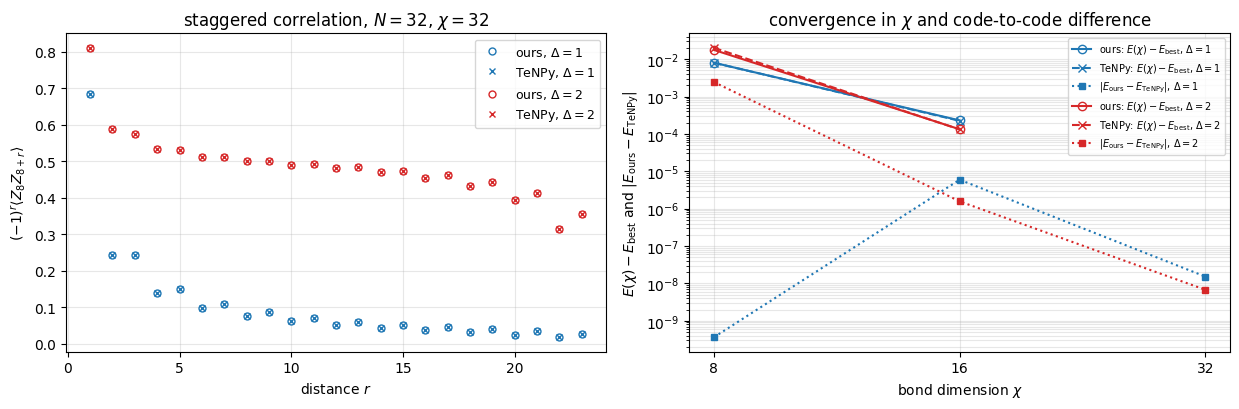

In [11]:
# ==============================================================================
# CHECKPOINTS and FIGURE: XXZ chain
# ==============================================================================
for Delta in DELTAS:
    for chi in CHIS[1:]:
        d, d_half = xxz[(Delta, chi)], xxz[(Delta, chi // 2)]
        tol_E = max(abs(d_half["E_o"] - d["E_o"]), abs(d_half["E_t"] - d["E_t"]))   # truncation error at chi/2 >= at chi
        assert abs(d["E_o"] - d["E_t"]) < tol_E, (Delta, chi)
    d = xxz[(Delta, 32)]
    tol = 10 * np.sqrt(max(d["eps_o"], d["eps_t"]))       # observables: error ~ sqrt(discarded weight), no TOL needed
    assert abs(d["S_o"] - d["S_t"]) < tol and np.max(np.abs(d["C_o"] - d["C_t"])) < tol, Delta
print("XXZ checkpoints passed")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
for Delta, c in zip(DELTAS, ("C0", "C3")):
    d = xxz[(Delta, 32)]
    ax.plot(d["rs"], d["C_o"], "o", color=c, ms=5, mfc="none", label=rf"ours, $\Delta={Delta:g}$")
    ax.plot(d["rs"], d["C_t"], "x", color=c, ms=5, label=rf"TeNPy, $\Delta={Delta:g}$")
ax.set_xlabel("distance $r$"); ax.set_ylabel(r"$(-1)^r\langle Z_8Z_{8+r}\rangle$")
ax.set_title(rf"staggered correlation, $N={N_X}$, $\chi=32$"); ax.grid(alpha=0.3); ax.legend(fontsize=9)
ax = axes[1]
for Delta, c in zip(DELTAS, ("C0", "C3")):
    E_best = min(xxz[(Delta, 32)]["E_o"], xxz[(Delta, 32)]["E_t"])
    ax.semilogy(CHIS[:-1], [xxz[(Delta, ch)]["E_o"] - E_best for ch in CHIS[:-1]], "o-", color=c, mfc="none",
                label=rf"ours: $E(\chi)-E_{{\rm best}}$, $\Delta={Delta:g}$")
    ax.semilogy(CHIS[:-1], [xxz[(Delta, ch)]["E_t"] - E_best for ch in CHIS[:-1]], "x--", color=c,
                label=rf"TeNPy: $E(\chi)-E_{{\rm best}}$, $\Delta={Delta:g}$")
    ax.semilogy(CHIS, [abs(xxz[(Delta, ch)]["E_o"] - xxz[(Delta, ch)]["E_t"]) for ch in CHIS], "s:", color=c, ms=4,
                label=rf"$\vert E_{{\rm ours}}-E_{{\rm TeNPy}}\vert$, $\Delta={Delta:g}$")
ax.set_xscale("log", base=2); ax.set_xticks(CHIS); ax.set_xticklabels([str(c) for c in CHIS])
ax.set_xlabel(r"bond dimension $\chi$"); ax.set_ylabel(r"$E(\chi)-E_{\rm best}$ and $\vert E_{\rm ours}-E_{\rm TeNPy}\vert$")
ax.set_title(r"convergence in $\chi$ and code-to-code difference"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

*Left*: the staggered correlations of the two codes lie on top of each other. At $\Delta=2$ they fall slowly, from $0.53$ at $r=4$ to $0.44$
at $r=19$ (Néel order); at $\Delta=1$ they decay towards zero ($0.14$ at $r=4$, $0.04$ at $r=19$), as at a critical point; the scatter at the largest $r$ comes from the open
end of the chain, which site $8+r$ approaches.
*Right*: the energy above the best value found (the lower of the two $\chi=32$ energies) falls rapidly with $\chi$ in both
codes, and the code-to-code difference stays below it. Two codes "agree" here in the precise sense that their difference is
smaller than the error each of them reports for itself.

> **Numerical practice.** Set the tolerance of a cross-check *before* looking at the numbers, from an error estimate of each
> code (here the $\chi$-convergence). A tolerance tuned afterwards to make the comparison pass proves nothing.

## 4. Time evolution with TEBD

### 4.1 The same Trotter splitting in both codes

Our `mps_tebd_evolve` performs second-order steps of the symmetric splitting introduced in [[9]](#ref-9),

$$ e^{-iH\delta t}\approx e^{-iH_{\rm e}\delta t/2}\,e^{-iH_{\rm o}\delta t}\,e^{-iH_{\rm e}\delta t/2}, \tag{6}$$

where $H_{\rm e}$ collects the bonds $(0,1),(2,3),\dots$ and $H_{\rm o}$ the bonds $(1,2),(3,4),\dots$. TeNPy's documentation describes
its second-order scheme in the same words, $e^{A/2}e^{B}e^{A/2}$, but whether $A$ is our $H_{\rm e}$ or $H_{\rm o}$ depends on how it numbers bonds,
and the two orderings have *different* Trotter errors. The source answers it: TeNPy's bond $i$ joins sites $(i-1,i)$, its
second-order sequence begins with a half step on its *odd* bonds $i=1,3,\dots$, i.e. on the sites $(0,1),(2,3),\dots$ — our $H_{\rm e}$.
The splittings are identical. Two further details:

* Within one call that evolves $n$ steps, TeNPy merges the half step that ends a step with the half step that begins the next,
  $e^{-iH_{\rm e}\delta t/2}e^{-iH_{\rm e}\delta t/2}=e^{-iH_{\rm e}\delta t}$. Without truncation this changes nothing; with truncation it means fewer
  truncations than in our code (which truncates after every layer).
* The two-site update is the same in both codes: merge the two tensors, apply the gate, multiply by the Schmidt values on the
  left, SVD, keep $\chi$ values, and compute the new left tensor without dividing by Schmidt values (TeNPy: `TEBDEngine.update_bond`).

The TEBD comparisons use zero field, so the question of how a code distributes single-site terms over the bonds of a Trotter
step, which changes only the Trotter error, does not arise.

### 4.2 TeNPy's accumulated discarded weight counts each truncation twice

The discarded weight is the quantity we use to decide whether a TEBD run can be trusted, so we check how TeNPy reports it before
relying on it. A TEBD engine offers `trunc_err` (the accumulated truncation error) and `trunc_err_bonds` (one entry per bond). The
checkpoint below evolves a short chain twice and compares them.

In [12]:
# ==============================================================================
# CHECKPOINT: two ways of reading TeNPy's discarded weight
# ==============================================================================
def tenpy_product_state(model, spec):
    """TeNPy MPS of our product state spec ('0' = up, '1' = down)."""
    return MPS.from_product_state(model.lat.mps_sites(), ["up" if c == "0" else "down" for c in spec],
                                  bc="finite", unit_cell_width=model.lat.mps_unit_cell_width)


m_q = tenpy_xxz(20, 1.0, 0.0)
eng_q = TEBDEngine(tenpy_product_state(m_q, "0" * 10 + "1" * 10), m_q,
                   dict(order=2, dt=0.05, N_steps=10, trunc_params=dict(chi_max=8, svd_min=1e-14, trunc_cut=None)))
eng_q.run(); eng_q.run()
eps_attr = eng_q.trunc_err.eps
eps_bonds = sum(t.eps for t in eng_q.trunc_err_bonds)
print(f"eng.trunc_err.eps             = {eps_attr:.6e}")
print(f"sum of eng.trunc_err_bonds    = {eps_bonds:.6e}")
print(f"ratio                         = {eps_attr / eps_bonds:.6f}")

eng.trunc_err.eps             = 6.132716e-07
sum of eng.trunc_err_bonds    = 3.066358e-07
ratio                         = 2.000000


The two numbers differ by exactly a factor of two. The source of the installed version shows why: `evolve` adds the error of each
call to `trunc_err`, and `run_evolution`, which calls `evolve`, adds the same error again. The per-bond record is updated once per
truncation, and its sum is the quantity that our engine reports, $\sum\varepsilon$ over all truncations. The double count affects
`TEBDEngine` and most engines derived from it when they are advanced with `run()` (`TimeDependentTEBD` has its own loop and counts once); `evolve()` called directly counts each error once,
and the overlap `trunc_err.ov` is squared in the same way. Below we read TeNPy's discarded weight from `trunc_err_bonds`.

> **Common pitfall.** Diagnostic counters are code too, and less tested than the physics. A library's error estimate is checked
> like any other number before a conclusion rests on it.

### 4.3 The TEBD wrapper and the exact reference

The wrapper evolves in chunks of `every` steps (one TeNPy `run` per chunk) and measures after each chunk: $\langle Z_j\rangle$ for all
sites, the entropy of the central cut in bits, and the accumulated discarded weight. The free-fermion reference for the XX chain is
the one of [notebook 18, Section 10.1, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb), copied here: the
Jordan–Wigner transformation maps down spins to free fermions, $\langle Z_j\rangle=1-2C_{jj}$ with the correlation matrix
$C_{ij}=\langle c^\dagger_ic_j\rangle$, and the entropy follows from the eigenvalues of a block of $C$ (introduced in [[10]](#ref-10)).

In [13]:
# ==============================================================================
# TEBD with TeNPy, and the exact free-fermion reference
# ==============================================================================
def tenpy_tebd(model, spec, chi, dt, n_steps, every):
    """Second-order TEBD with TeNPy from the product state spec; measurements after every `every` steps.

    RETURNS  z (n_steps//every, N) <Z_j>,  S (n_steps//every,) central entropy in bits,
             eps (n_steps//every,) accumulated discarded weight (sum over trunc_err_bonds, see Sec. 4.2), wall time.
    """
    psi = tenpy_product_state(model, spec)
    N = psi.L
    eng = TEBDEngine(psi, model, dict(order=2, dt=dt, N_steps=every,
                                      trunc_params=dict(chi_max=chi, svd_min=1e-14, trunc_cut=None)))
    z, S, eps = [], [], []
    t0 = time.perf_counter()
    for _ in range(n_steps // every):
        eng.run()
        z.append(2.0 * psi.expectation_value("Sz"))
        S.append(bits(psi.entanglement_entropy(bonds=[N // 2])[0]))
        eps.append(sum(t.eps for t in eng.trunc_err_bonds))
    return np.array(z), np.array(S), np.array(eps), time.perf_counter() - t0


def xx_free_fermion_reference(spec, J, times, cut):
    """Exact <Z_j(t)> and entanglement entropy (bits) of the block {0..cut-1} for H = J sum (XX+YY), product initial state.

    MATH   down spin ('1') = fermion;  h1[j,j+1] = h1[j+1,j] = 2J;  U(t) = exp(-i h1 t);
           C(t) = U[:,occ]^* U[:,occ]^T;  <Z_j> = 1 - 2 C_jj;  S = -sum nu log2 nu + (1-nu) log2(1-nu), nu = eig(C[:cut,:cut]).
    COST   O(N^3) per time."""
    N = len(spec)
    occ = [j for j, c in enumerate(spec) if c == "1"]
    h1 = 2.0 * J * (np.eye(N, k=1) + np.eye(N, k=-1))
    w, V = np.linalg.eigh(h1)
    z, S = [], []
    for t in times:
        U = (V * np.exp(-1j * w * t)) @ V.conj().T
        C = U[:, occ].conj() @ U[:, occ].T
        z.append(1.0 - 2.0 * np.real(np.diag(C)))
        nu = np.clip(np.linalg.eigvalsh(C[:cut, :cut]), 1e-15, 1 - 1e-15)
        S.append(-np.sum(nu * np.log2(nu) + (1 - nu) * np.log2(1 - nu)))
    return np.array(z), np.array(S)

**The tolerance.** Without truncation the two codes apply the same gates in the same order, so they must agree to rounding. With
truncation each code's state departs from the untruncated Trotter state. A truncation with discarded weight $\varepsilon$ moves the
normalised state by $\Vert\psi-\tilde\psi\Vert\le\sqrt{2\varepsilon}$ (for small $\varepsilon$ the distance is $\sqrt\varepsilon$ to leading order), the unitary gates
that follow do not change distances, and by the triangle inequality the distance after many truncations is at most the sum of the
individual distances. For an observable with $\Vert O\Vert=1$, $\vert\langle\psi\vert O\vert\psi\rangle-\langle\tilde\psi\vert O\vert\tilde\psi\rangle\vert\le2\Vert\psi-\tilde\psi\Vert$. Our engine
returns $\sum\sqrt{\varepsilon}$ over its truncations; TeNPy returns only $\sum\varepsilon$ over its $n$ truncations, and the Cauchy–Schwarz inequality gives
$\sum\sqrt{\varepsilon}\le\sqrt{n\sum\varepsilon}$. The bound on the code-to-code difference of $\langle Z_j\rangle$ is therefore

$$ \vert\Delta\langle Z_j\rangle\vert\le2\sqrt2\left(\textstyle\sum\sqrt{\varepsilon_{\rm ours}}+\sqrt{n_{\rm TeNPy}\sum\varepsilon_{\rm TeNPy}}\right) . \tag{7}$$

For $n_{\rm TeNPy}$ we take the number of two-site updates of an unmerged Strang step, $2\cdot\frac N2+(\frac N2-1)$, which is $2\cdot20+19=59$ for $N=40$,
times the number of steps. Merging half steps only lowers the true count, and a larger $n$ only loosens the bound.

The bound is rigorous when the $\varepsilon$ are the exact discarded Schmidt weights. In TEBD the canonical form holds only approximately
after truncations, so the $\varepsilon$ are close estimates. The bound is far from tight; the run must satisfy it at every time, and it says
nothing when it exceeds $2$.

### 4.4 The domain wall in the XX chain

We start from $\vert\!\uparrow\cdots\uparrow\downarrow\cdots\downarrow\rangle$ in the XX chain $H=\sum_i(X_iX_{i+1}+Y_iY_{i+1})$, $N=40$, $\chi=32$,
$\delta t=0.05$, up to $t=5$, and measure every five steps.

In [14]:
# ==============================================================================
# PARAMETERS and EXPERIMENT: domain-wall quench, ours vs TeNPy vs exact
# ==============================================================================
N_Q, DT_Q = 40, 0.05
CHI_DW, STEPS_DW = 32, 100
SPEC_DW = "0" * (N_Q // 2) + "1" * (N_Q // 2)
h_xx = bond_hamiltonians(N_Q, Jxx=1.0, Jyy=1.0)        # ours:  H = sum (X X + Y Y)
model_xx = tenpy_xxz(N_Q, 1.0, 0.0)                    # TeNPy: the same H through the dictionary of Eq. (3)


def compare_quench(spec, chi, n_steps, every, h_bonds, model, reference=None):
    """Run ours (bond Hamiltonians h_bonds) and TeNPy (model) from the same product state spec, with time step DT_Q.

    The caller passes BOTH descriptions of the same H: h_bonds for our engine and the TeNPy model built with the
    dictionary of Sec. 2 -- nothing is taken from a global, so the two runs cannot silently simulate different chains.
    TeNPy evolves `every` steps per call (merging half steps when every > 1); both are measured at t = every*dt, 2*every*dt, ...
    reference: None, or a function times -> (z, S) giving the exact <Z_j(t)> and central entropy (bits).
    RETURNS  dict of the measured arrays, the bound of Eq. (7) and the code-to-code difference dz = max_j |Z_ours - Z_TeNPy|."""
    t0 = time.perf_counter()
    (_, _), out = mps_tebd_evolve(*product_mps(spec, chi), h_bonds, DT_Q, n_steps)
    jax.block_until_ready(out)
    t_o = time.perf_counter() - t0
    N = len(spec)
    sel = slice(every - 1, None, every)                  # our measurements at the times TeNPy measures
    z_o, S_o = np.asarray(out["z"])[sel], np.asarray(out["S"])[sel, N // 2]
    sqeps_o = np.cumsum(np.asarray(out["sqeps"]))[sel]
    eps_o = np.cumsum(np.asarray(out["eps"]))[sel]
    z_t, S_t, eps_t, t_t = tenpy_tebd(model, spec, chi, DT_Q, n_steps, every)
    times = DT_Q * every * np.arange(1, n_steps // every + 1)
    n_t = (2 * (N // 2) + (N // 2 - 1)) * every * np.arange(1, n_steps // every + 1)   # n_TeNPy of Eq. (7)
    bound = 2 * np.sqrt(2) * (sqeps_o + np.sqrt(n_t * eps_t))
    z_x, S_x = reference(times) if reference is not None else (None, None)
    return dict(t=times, z_o=z_o, z_t=z_t, z_x=z_x, S_o=S_o, S_t=S_t, S_x=S_x, eps_o=eps_o, eps_t=eps_t, bound=bound,
                dz=np.max(np.abs(z_o - z_t), axis=1), t_o=t_o, t_t=t_t)


dw = compare_quench(SPEC_DW, CHI_DW, STEPS_DW, 5, h_xx, model_xx,
                    reference=lambda times: xx_free_fermion_reference(SPEC_DW, 1.0, times, N_Q // 2))
clean = (dw["eps_o"] < 1e-20) & (dw["eps_t"] < 1e-20)
print(f"N = {N_Q}, chi = {CHI_DW}, dt = {DT_Q}, t <= {dw['t'][-1]:.0f}   [ours {dw['t_o']:.1f} s incl. compilation, TeNPy {dw['t_t']:.1f} s]")
print(f"{'t':>5} | {'max|dZ| ours-TeNPy':>18} | {'bound (7)':>9} | {'max|Z_ours-exact|':>17} | {'max|Z_TeNPy-exact|':>18} | "
      f"{'sum eps ours':>12} | {'sum eps TeNPy':>13}")
for k in range(0, len(dw["t"]), 2):
    print(f"{dw['t'][k]:5.2f} | {dw['dz'][k]:18.1e} | {dw['bound'][k]:9.1e} | {np.max(np.abs(dw['z_o'][k] - dw['z_x'][k])):17.1e} | "
          f"{np.max(np.abs(dw['z_t'][k] - dw['z_x'][k])):18.1e} | {dw['eps_o'][k]:12.1e} | {dw['eps_t'][k]:13.1e}")
print(f"\nwhile both discarded weights are below 1e-20 (t <= {dw['t'][clean][-1]:.2f}): max|dZ| ours-TeNPy = {dw['dz'][clean].max():.1e}")
print(f"over the whole run: max|dZ| ours-TeNPy = {dw['dz'].max():.1e},  max|dS_mid| = {np.max(np.abs(dw['S_o'] - dw['S_t'])):.1e} bits")
print(f"Trotter error shared by both: max|Z - exact| = {np.max(np.abs(dw['z_o'] - dw['z_x'])):.2e} (ours), "
      f"{np.max(np.abs(dw['z_t'] - dw['z_x'])):.2e} (TeNPy)")
assert dw["dz"][clean].max() < 10 * TOL                   # identical gates, no truncation: rounding only
assert np.all(dw["dz"] <= dw["bound"])                    # Eq. (7) at every time

N = 40, chi = 32, dt = 0.05, t <= 5   [ours 5.6 s incl. compilation, TeNPy 11.3 s]
    t | max|dZ| ours-TeNPy | bound (7) | max|Z_ours-exact| | max|Z_TeNPy-exact| | sum eps ours | sum eps TeNPy
 0.25 |            8.9e-16 |   1.5e-12 |           6.8e-04 |            6.8e-04 |      9.2e-29 |       4.2e-28
 0.75 |            1.1e-14 |   2.6e-09 |           1.0e-03 |            1.0e-03 |      8.8e-22 |       8.8e-22
 1.25 |            1.2e-14 |   8.7e-06 |           1.3e-03 |            1.3e-03 |      5.8e-15 |       5.8e-15
 1.75 |            1.1e-11 |   4.6e-04 |           1.5e-03 |            1.5e-03 |      1.1e-11 |       1.1e-11
 2.25 |            3.0e-09 |   5.8e-03 |           1.6e-03 |            1.6e-03 |      1.2e-09 |       1.3e-09
 2.75 |            3.5e-07 |   2.4e-02 |           1.8e-03 |            1.8e-03 |      1.6e-08 |       1.8e-08
 3.25 |            1.8e-05 |   5.9e-02 |           1.9e-03 |            1.9e-03 |      7.4e-08 |       8.2e-08
 3.75 |            9.7e-05 | 

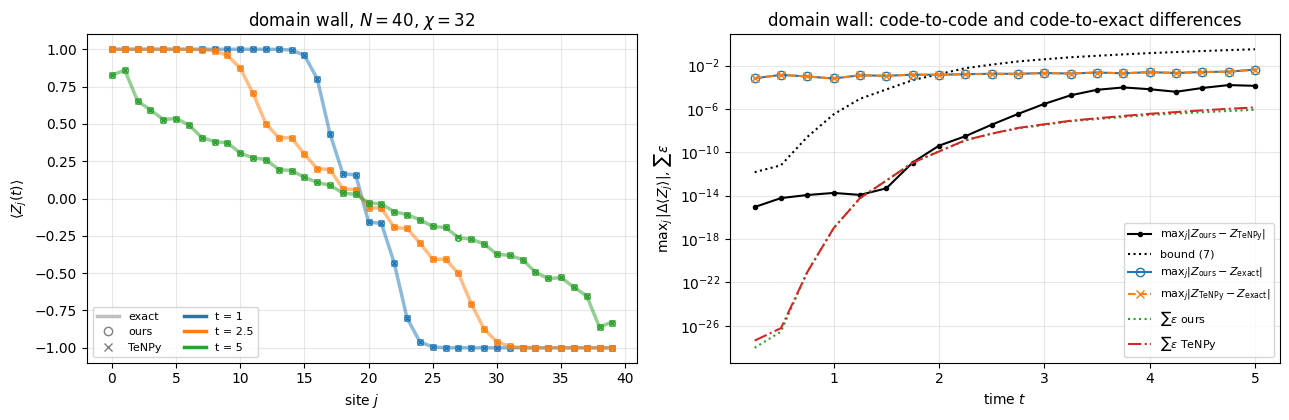

In [15]:
# ------------------------------------------------------------------------------
# FIGURE: domain wall -- profiles and the three differences
# ------------------------------------------------------------------------------
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for k, c in zip((3, 9, 19), ("C0", "C1", "C2")):
    ax.plot(np.arange(N_Q), dw["z_x"][k], "-", color=c, lw=2.5, alpha=0.5)
    ax.plot(np.arange(N_Q), dw["z_o"][k], "o", color=c, ms=4, mfc="none")
    ax.plot(np.arange(N_Q), dw["z_t"][k], "x", color=c, ms=4)
handles = ([Line2D([], [], color="gray", lw=2.5, alpha=0.5, label="exact"),
            Line2D([], [], color="gray", marker="o", mfc="none", ls="none", label="ours"),
            Line2D([], [], color="gray", marker="x", ls="none", label="TeNPy")]
           + [Line2D([], [], color=c, lw=2.5, label=f"t = {dw['t'][k]:g}") for k, c in zip((3, 9, 19), ("C0", "C1", "C2"))])
ax.set_xlabel("site $j$"); ax.set_ylabel(r"$\langle Z_j(t)\rangle$"); ax.set_title(rf"domain wall, $N={N_Q}$, $\chi={CHI_DW}$")
ax.grid(alpha=0.3); ax.legend(handles=handles, loc="lower left", fontsize=8, ncol=2)
ax = axes[1]
ax.semilogy(dw["t"], np.clip(dw["dz"], 1e-17, None), "k.-", label=r"$\mathrm{max}_j\vert Z_{\rm ours}-Z_{\rm TeNPy}\vert$")
ax.semilogy(dw["t"], dw["bound"], "k:", lw=1.5, label="bound (7)")
ax.semilogy(dw["t"], np.max(np.abs(dw["z_o"] - dw["z_x"]), axis=1), "C0o-", mfc="none", label=r"$\mathrm{max}_j\vert Z_{\rm ours}-Z_{\rm exact}\vert$")
ax.semilogy(dw["t"], np.max(np.abs(dw["z_t"] - dw["z_x"]), axis=1), "C1x--", label=r"$\mathrm{max}_j\vert Z_{\rm TeNPy}-Z_{\rm exact}\vert$")
ax.semilogy(dw["t"], np.clip(dw["eps_o"], 1e-30, None), "C2:", label=r"$\sum\varepsilon$ ours")
ax.semilogy(dw["t"], np.clip(dw["eps_t"], 1e-30, None), "C3-.", label=r"$\sum\varepsilon$ TeNPy")
ax.set_xlabel("time $t$"); ax.set_ylabel(r"$\mathrm{max}_j\,\vert\Delta\langle Z_j\rangle\vert$, $\sum\varepsilon$")
ax.set_title("domain wall: code-to-code and code-to-exact differences")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Three regimes are visible:

* **Before truncation sets in** both discarded weights are below $10^{-20}$, the codes apply the same gates in the same order, and they agree
  to rounding. This confirms the bond numbering of Sec. 4.1: the other ordering of the Strang step produces a different state, at a
  distance of order $\delta t^2$ (about $10^{-3}$ at $t=0.75$, comparable to the shared Trotter error and eleven orders of magnitude above
  the observed agreement; Exercise 4).
* **After truncation sets in** the code-to-code difference grows with the accumulated discarded weight, staying far inside the
  bound (7). The two codes truncate at slightly different moments (TeNPy merges half steps) and accumulate slightly different
  discarded weights, so they no longer follow the same trajectory, but both stay close to the untruncated one.
* **Against the exact solution** both codes are off by the same few times $10^{-3}$, much more than they differ from each other. This is
  the Trotter error of $\delta t=0.05$, which they share because they use the same splitting. The agreement of the two codes says nothing about it;
  only the exact reference does.

### 4.5 The Néel state: agreeing on a wrong answer

The Néel state $\vert\!\uparrow\downarrow\uparrow\downarrow\cdots\rangle$ in the XX chain generates entanglement linearly in time, so a fixed $\chi$
fails after a time that grows only like $\log\chi$ (see [notebook 18, Section 10.3, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb)).
We evolve to $t=2$ with $\chi=16$ and $\chi=32$, well beyond the time at which either is accurate. Here TeNPy evolves one step per call,
so that it performs exactly our sequence of gates and truncations (no merged half steps), and we measure after every step. To see how much
of a code-to-code difference is a property of the method, TeNPy is run at $\chi=32$ a second time without $S^z$ conservation
(`conserve=None`): the same algorithm, with only the internal block structure of its tensors changed.

In [16]:
# ==============================================================================
# EXPERIMENT: Neel quench beyond the reach of chi, ours vs TeNPy (with and without Sz conservation) vs exact
# ==============================================================================
SPEC_NEEL, STEPS_NEEL = "01" * (N_Q // 2), 40
model_xx_noconserve = tenpy_xxz(N_Q, 1.0, 0.0, conserve=None)
neel_exact = lambda times: xx_free_fermion_reference(SPEC_NEEL, 1.0, times, N_Q // 2)
neel = {}
for chi in (16, 32):
    neel[chi] = compare_quench(SPEC_NEEL, chi, STEPS_NEEL, 1, h_xx, model_xx, reference=neel_exact)
    d = neel[chi]
    if chi == 32:
        z_t2, _, _, _ = tenpy_tebd(model_xx_noconserve, SPEC_NEEL, chi, DT_Q, STEPS_NEEL, 1)
        d["dz_self"] = np.max(np.abs(d["z_t"] - z_t2), axis=1)
    print(f"chi = {chi}, t <= {d['t'][-1]:.0f}:   [ours {d['t_o']:.1f} s, TeNPy {d['t_t']:.1f} s]")
    print(f"{'t':>6} | {'max|dZ| ours-TeNPy':>18} | {'TeNPy(Sz)-TeNPy(None)':>21} | {'max|Z_ours-exact|':>17} | "
          f"{'max|Z_TeNPy-exact|':>18} | {'sum eps ours':>12} | {'sum eps TeNPy':>13}")
    for k in range(3, len(d["t"]), 4):
        self_k = f"{d['dz_self'][k]:21.1e}" if chi == 32 else f"{'-':>21}"
        print(f"{d['t'][k]:6.2f} | {d['dz'][k]:18.1e} | {self_k} | {np.max(np.abs(d['z_o'][k] - d['z_x'][k])):17.2e} | "
              f"{np.max(np.abs(d['z_t'][k] - d['z_x'][k])):18.2e} | {d['eps_o'][k]:12.1e} | {d['eps_t'][k]:13.1e}")
    print(f"   central entropy at t = 2: ours {d['S_o'][-1]:.4f}, TeNPy {d['S_t'][-1]:.4f}, exact {d['S_x'][-1]:.4f} bits")
    print(f"   whole run: max|dZ| ours-TeNPy = {d['dz'].max():.1e}" + (f", TeNPy(Sz)-TeNPy(None) = {d['dz_self'].max():.1e}" if chi == 32 else "")
          + f";  first time with max|dZ| ours-TeNPy > 1e-8: " + (f"t = {d['t'][np.argmax(d['dz'] > 1e-8)]:.2f}" if np.any(d["dz"] > 1e-8) else "none"))
    # growth of the code-to-code difference per time step, once it is above the rounding level (1e-12) and below 1e-2
    grow = d["dz"][1:] / np.maximum(d["dz"][:-1], 1e-300)
    win = (d["dz"][:-1] > 1e-12) & (d["dz"][1:] < 1e-2)
    print(f"   growth factor of max|dZ| ours-TeNPy per step (from 1e-12 to 1e-2): "
          + (f"largest {grow[win].max():.0f} (t = {d['t'][1:][win][np.argmax(grow[win])]:.2f}), median {np.median(grow[win]):.1f}" if np.any(win) else "-") + "\n")

assert neel[16]["dz"].max() < 100 * TOL                                  # the two codes agree ...
assert np.max(np.abs(neel[16]["z_o"][-1] - neel[16]["z_x"][-1])) > 0.5   # ... on a wrong answer
assert neel[16]["eps_o"][-1] > 0.1 and neel[16]["eps_t"][-1] > 0.1       # which both discarded weights flag
assert np.all(neel[32]["dz"] <= neel[32]["bound"])                       # Eq. (7)
assert neel[32]["dz_self"].max() > 0.1 * neel[32]["dz"].max()            # TeNPy differs from itself on the same scale

chi = 16, t <= 2:   [ours 2.1 s, TeNPy 7.4 s]
     t | max|dZ| ours-TeNPy | TeNPy(Sz)-TeNPy(None) | max|Z_ours-exact| | max|Z_TeNPy-exact| | sum eps ours | sum eps TeNPy
  0.20 |            2.3e-15 |                     - |          4.54e-04 |           4.54e-04 |      1.4e-19 |       1.4e-19
  0.40 |            3.8e-15 |                     - |          1.07e-03 |           1.07e-03 |      1.3e-12 |       1.3e-12
  0.60 |            9.5e-15 |                     - |          8.24e-04 |           8.24e-04 |      3.2e-08 |       3.2e-08
  0.80 |            1.3e-14 |                     - |          7.65e-04 |           7.65e-04 |      1.3e-05 |       1.3e-05
  1.00 |            1.6e-11 |                     - |          8.67e-04 |           8.67e-04 |      1.7e-04 |       1.7e-04
  1.20 |            7.9e-11 |                     - |          4.38e-03 |           4.38e-03 |      2.6e-03 |       2.6e-03
  1.40 |            1.2e-10 |                     - |          4.02e-02 |           4.

chi = 32, t <= 2:   [ours 3.8 s, TeNPy 8.2 s]
     t | max|dZ| ours-TeNPy | TeNPy(Sz)-TeNPy(None) | max|Z_ours-exact| | max|Z_TeNPy-exact| | sum eps ours | sum eps TeNPy
  0.20 |            3.3e-15 |               3.7e-15 |          4.54e-04 |           4.54e-04 |      1.1e-28 |       6.0e-27
  0.40 |            4.1e-15 |               1.1e-14 |          1.07e-03 |           1.07e-03 |      6.6e-20 |       6.6e-20
  0.60 |            8.6e-15 |               7.5e-15 |          8.24e-04 |           8.24e-04 |      3.7e-14 |       3.7e-14
  0.80 |            9.9e-15 |               8.8e-15 |          7.65e-04 |           7.65e-04 |      3.2e-10 |       3.2e-10
  1.00 |            5.9e-14 |               1.3e-14 |          8.85e-04 |           8.85e-04 |      2.5e-07 |       2.5e-07
  1.20 |            2.4e-13 |               6.1e-14 |          1.92e-03 |           1.92e-03 |      5.1e-05 |       5.1e-05
  1.40 |            1.9e-07 |               8.0e-08 |          7.65e-04 |           7.

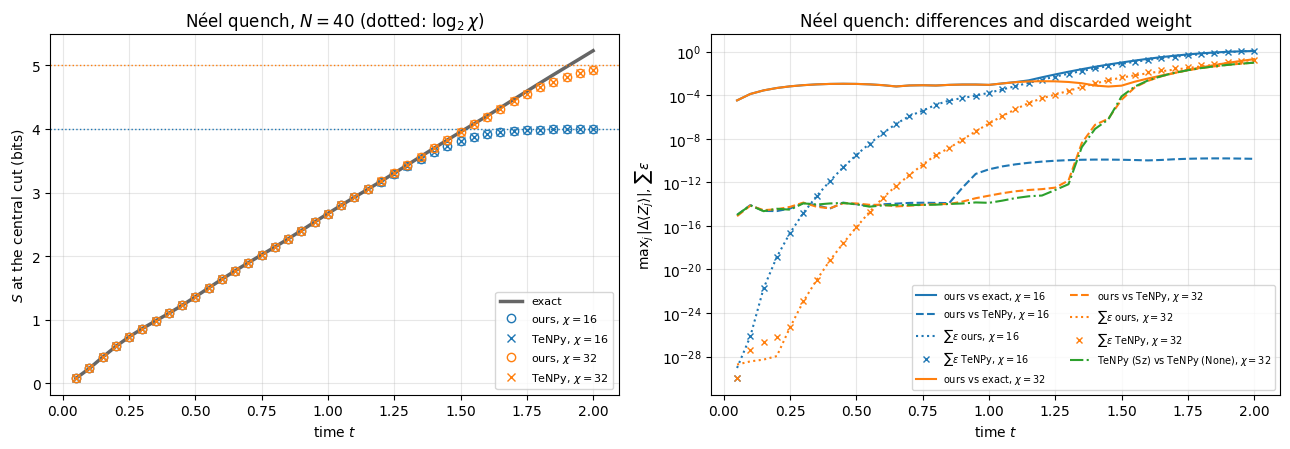

In [17]:
# ------------------------------------------------------------------------------
# FIGURE: Neel quench -- entropy and errors
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(neel[16]["t"], neel[16]["S_x"], "k-", lw=2.5, alpha=0.6, label="exact")
for chi, c in ((16, "C0"), (32, "C1")):
    ax.plot(neel[chi]["t"], neel[chi]["S_o"], "o", color=c, mfc="none", label=rf"ours, $\chi={chi}$")
    ax.plot(neel[chi]["t"], neel[chi]["S_t"], "x", color=c, label=rf"TeNPy, $\chi={chi}$")
    ax.axhline(np.log2(chi), color=c, ls=":", lw=1)
ax.set_xlabel("time $t$"); ax.set_ylabel(r"$S$ at the central cut (bits)"); ax.set_title(rf"Néel quench, $N={N_Q}$ (dotted: $\log_2\chi$)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax = axes[1]
for chi, c in ((16, "C0"), (32, "C1")):
    d = neel[chi]
    ax.semilogy(d["t"], np.max(np.abs(d["z_o"] - d["z_x"]), axis=1), "-", color=c, label=rf"ours vs exact, $\chi={chi}$")
    ax.semilogy(d["t"], np.clip(d["dz"], 1e-17, None), "--", color=c, label=rf"ours vs TeNPy, $\chi={chi}$")
    ax.semilogy(d["t"], np.clip(d["eps_o"], 1e-30, None), ":", color=c, label=rf"$\sum\varepsilon$ ours, $\chi={chi}$")
    ax.semilogy(d["t"], np.clip(d["eps_t"], 1e-30, None), "x", color=c, ms=4, label=rf"$\sum\varepsilon$ TeNPy, $\chi={chi}$")
ax.semilogy(neel[32]["t"], np.clip(neel[32]["dz_self"], 1e-17, None), "-.", color="C2",
            label=r"TeNPy (Sz) vs TeNPy (None), $\chi=32$")
ax.set_xlabel("time $t$"); ax.set_ylabel(r"$\mathrm{max}_j\,\vert\Delta\langle Z_j\rangle\vert$, $\sum\varepsilon$")
ax.set_title("Néel quench: differences and discarded weight"); ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=7, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

**$\chi=16$.** The two codes agree to $2\times10^{-10}$ at every time, while both are wrong by order one at $t=2$: the exact entropy has grown to
$5.2$ bits, beyond the $\log_2 16=4$ bits that an MPS of bond dimension $16$ can hold. Both codes apply the same gates and the same truncation
rule, so they compute the same sequence of truncated states up to rounding, and here the rounding differences stay at $10^{-10}$: the
printed growth factor of the code-to-code difference per step is at most $3$. A cross-check between two implementations of *the same
approximation* cannot detect the error of that approximation. The run at $\chi=32$ shows that even the agreement is not guaranteed.

**$\chi=32$.** The codes agree to rounding up to $t=1.2$; by $t=1.4$ the difference has jumped by six orders of magnitude, to $2\times10^{-7}$, and it
grows to about $0.1$ at $t=2$, inside the bound (7). The two TeNPy runs, which differ only in how the tensors are organised internally, separate at the same
time and by the same amount. Keeping the $\chi$ largest Schmidt values is a nonlinear operation. Repeated at every bond of
every step, it can amplify a small difference between two states, which the unitary gates alone never do. Here a rounding difference is
amplified: the code-to-code difference grows by a factor of up to $2729$ in a single step (at $t=1.35$), where at $\chi=16$ it hardly grew. From then on the two runs follow different trajectories, separated by an amount bounded by Eq. (7), i.e. of order
$\sqrt{\sum\varepsilon}$. The divergence is a property of the method at this $\chi$. In both cases the discarded weight reported by each code
is the signal that the results are unreliable. In the figure, the flat part of the solid curves near $10^{-3}$ (up to $t\approx1$ at $\chi=16$
and $t\approx1.4$ at $\chi=32$) is the Trotter error of $\delta t=0.05$, which both codes share.

> **Numerical practice.** In a production run with no exact reference, the test is convergence in $\chi$ and $\delta t$ within one
> code, guided by the discarded weight. A second code tests the implementation; only convergence or an exact result tests the
> approximation.

## 5. What agreement between two codes proves

Which errors each test detects:

| error | example | ours vs TeNPy | exact reference | $\chi$/$\delta t$ convergence of one code |
|---|---|---|---|---|
| a bug in one code (wrong contraction, wrong bond) | an environment updated with the wrong site | yes | yes | no (in general) |
| a convention error in the *mapping* to the second code | $J_{xx}=J$ instead of $4J$ | yes (Sec. 2.4) | yes | no |
| a convention error shared by both inputs | a typo in $\Delta$ used to set up both runs | no | yes | no |
| an error of the shared approximation | the Trotter error of $\delta t$ (Sec. 4.4) | no | yes | yes ($\delta t$) |
| the shared truncation | $\chi=16$ for the Néel quench (Sec. 4.5) | no | yes | yes ($\chi$) |
| a legitimate difference of the state found | cat versus symmetry-broken state (Sec. 3.1) | flagged; a legitimate difference | resolved by physics | no |

Each column catches a different set of rows. Agreement is evidence that *both codes compute the same mathematical object*: the same
$H$, the same algorithm, the same approximation. It does not show that this object is the physical answer. That requires either an
independent exact result (free fermions, a conservation law, a known limit) or a convergence study in the control parameters ($\chi$,
$\delta t$, the number of sweeps). The analytic references in this notebook break the symmetry between the two codes: an error that both
share is invisible to their comparison and visible to an exact solution.

## 6. Summary - key takeaways

* A cross-check starts with the **dictionary between conventions**: for the XXZ chain $J_{xx}=4J$, $J_z=4J\Delta$, $h_z^{\rm TeNPy}=-2h_z$
  (spin-1/2 versus Pauli operators); TeNPy's Ising chain is ours rotated by a Hadamard on every site ($g=h$, $\langle Z_iZ_j\rangle\leftrightarrow\langle\sigma^x_i\sigma^x_j\rangle$); entropies in nats versus bits.
* Test the dictionary on the **full Hamiltonian matrix** of a small chain: element by element where the bases agree, by the spectrum
  where they differ by a unitary.
* With a conserved charge a library may **reorder the local basis**; compare named observables, which do not depend on the order.
* DMRG energies of two codes at the same $\chi$ differ by much less than the **truncation error of either**, estimated from $\chi\to2\chi$; that
  estimate, set beforehand, is the tolerance. Entropies and correlations follow.
* In the ordered Ising phase the codes returned **different, equally valid states**: the cat ground state (TeNPy, with parity
  conservation) and the symmetry-broken state (ours), $s_{\min}$ apart in energy and one bit apart in entropy.
* TEBD with the **same Trotter splitting and ordering** agrees to rounding until truncation sets in and then within the discarded
  weight. Both codes share the Trotter error, which only the exact solution reveals.
* Two implementations of the same truncation can **agree to $10^{-10}$ on an answer that is wrong by order one**. Only the discarded
  weight flags it.
* Check the diagnostics of a library like its physics: TeNPy 1.1.0's accumulated `trunc_err` after `run()` counts each discarded
  weight twice; `trunc_err_bonds` does not.

## 7. Exercises

1. ★ **Field terms.** In the XXZ checkpoint of Sec. 2.4 (which has $h_z=0.3$), flip the sign of the field in the mapping
   ($h_z^{\rm TeNPy}=+2h_z$). Which matrix elements differ, and does the spectrum reveal the error? (Hint: what does the global spin flip
   $\prod_iX_i$ do to Eq. (1)?)
2. ★ **Symmetric quantities in the ordered phase.** Rerun the $h=0.5$ Ising comparison with `tenpy_tfi(..., conserve=None)` and
   compare $\langle Z_8\rangle$ (ours) with $\langle\sigma^x_8\rangle$ (TeNPy; with `conserve="parity"` the same call returns exactly $0$ by symmetry). Which
   state does TeNPy find without parity conservation? Then start TeNPy from the state with $\sigma^x_j=+1$ on every site (pass a list of
   the 2-vectors $(1,1)/\sqrt2$ to `MPS.from_product_state`) and explain why the start state matters.
3. ★★ **Trotter error without an exact solution.** Repeat the domain-wall run with $\delta t=0.025$ in both codes. Show that
   their difference from each other is unchanged in character while their common difference from the exact solution drops by
   a factor of four. How could you estimate the Trotter error from the two runs of *one* code alone?
4. ★★ **The other ordering.** Write a variant of `mps_tebd_evolve` that starts each Strang step with a half step on the bonds
   $(1,2),(3,4),\dots$ (build it from `tebd_layer` and `bond_gates` with the index arrays exchanged). Compare it with TeNPy in the
   domain-wall run without truncation (use $\chi=64$, or stop at $t=0.75$), at a fixed time for $\delta t=0.05$ and $\delta t=0.025$, and
   show that the difference is of order $\delta t^2$.
5. ★★★ **An interacting quench.** Repeat the Néel comparison for the XXZ chain at $\Delta=0.5$, where no exact solution exists, at
   $\chi=16,32,64$ up to $t=3$: pass `bond_hamiltonians(N_Q, Jxx=1.0, Jyy=1.0, Jzz=0.5)` and `tenpy_xxz(N_Q, 1.0, 0.5)` to
   `compare_quench` with `reference=None`. Decide from the discarded weight and the $\chi$-convergence up to which time either code can
   be trusted, and compare the code-to-code difference with $\sqrt{\sum\varepsilon}$ up to that time.
6. ★★★ **Extend the code: a third convention.** TeNPy also offers a general `SpinChain` model with spin $S$, couplings `Jx`, `Jy`, `Jz`
   in front of $S^a_iS^a_{i+1}$ and fields `hx`, `hy`, `hz` (read its docstring for the sign of the field terms). Write
   `tenpy_spin_chain(N, Jxx, Jyy, Jzz, hx, hz)` for our `xxz_mpo` with $S=1/2$, test it with `tenpy_mpo_to_dense`, and include a
   transverse field $h_x$. With $h_x\neq0$ the magnetisation $S^z_{\rm tot}$ is not conserved: use `conserve=None`, and check the order
   of the local basis (`state_labels` of the site) before comparing matrix elements.
7. ★★★ **Physics: the Néel order parameter.** Using both codes at $\Delta=2$ with $N=32,48,64$ and $\chi=32$, compute the plateau of the
   staggered correlation, defined as $C_{\rm st}=(-1)^{N/2}\langle Z_{N/4}Z_{3N/4}\rangle$. Check that a sixth sweep changes it by less than
   $10^{-4}$, extrapolate $C_{\rm st}(N)$ to $N\to\infty$ once linearly in $1/N$ and once with an exponential approach
   $C_\infty-b\,e^{-N/\xi}$ (as expected in a gapped phase), and compare both extrapolations with the exact staggered magnetisation squared
   $m_{\rm st}^2=0.538$ quoted in [notebook 18, Section 6.9, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb).

## 8. References

<span id="ref-1">[1]</span> J. Hauschild and F. Pollmann, *Efficient numerical simulations with Tensor Networks: Tensor Network Python (TeNPy)*, SciPost Phys. Lect. Notes **5** (2018). - the library and its MPS algorithms.

<span id="ref-2">[2]</span> J. Hauschild, J. Unfried, S. Anand *et al.*, *Tensor network Python (TeNPy) version 1*, SciPost Phys. Codebases **41** (2024). - the version 1 release used here.

<span id="ref-3">[3]</span> S. R. White, *Density matrix formulation for quantum renormalization groups*, Phys. Rev. Lett. **69**, 2863 (1992). - DMRG.

<span id="ref-4">[4]</span> G. Vidal, *Efficient classical simulation of slightly entangled quantum computations*, Phys. Rev. Lett. **91**, 147902 (2003). - TEBD.

<span id="ref-5">[5]</span> G. Vidal, *Efficient simulation of one-dimensional quantum many-body systems*, Phys. Rev. Lett. **93**, 040502 (2004). - TEBD for one-dimensional many-body systems.

<span id="ref-6">[6]</span> P. Jordan and E. Wigner, *Über das Paulische Äquivalenzverbot*, Z. Phys. **47**, 631 (1928). - the Jordan-Wigner transformation.

<span id="ref-7">[7]</span> E. Lieb, T. Schultz and D. Mattis, *Two soluble models of an antiferromagnetic chain*, Ann. Phys. **16**, 407 (1961). - the free-fermion method for quadratic fermion Hamiltonians.

<span id="ref-8">[8]</span> P. Pfeuty, *The one-dimensional Ising model with a transverse field*, Ann. Phys. **57**, 79 (1970). - the exact solution of the transverse-field Ising chain.

<span id="ref-9">[9]</span> G. Strang, *On the construction and comparison of difference schemes*, SIAM J. Numer. Anal. **5**, 506 (1968). - the symmetric second-order splitting.

<span id="ref-10">[10]</span> I. Peschel, *Calculation of reduced density matrices from correlation functions*, J. Phys. A **36**, L205 (2003). - entanglement entropy of free fermions from the correlation matrix.

---
Marcin Płodzień, PhD

**Citation:** M. Płodzień, *Quantum Many-Body Simulation: from a single spin to quantum machine learning* (2026), https://marcinplodzien.github.io/quantum-many-body-simulation/